# DATASET LOADING AND INFORMATION

In [1]:
# ============================================================
# STEP 1: DATASET LOADING AND INFORMATION
# Dataset: Sports Psychological Intervention
# ============================================================

import os
import pandas as pd
import numpy as np

# -------------------------------
# 1. Dataset Configuration
# -------------------------------

DATASET_PATH = r"F:\.0 Work\3805\sports_psych_intervention.csv"

print("=" * 65)
print("STEP 1: DATASET LOADING AND INFORMATION")
print("=" * 65)

# -------------------------------
# 2. Check Dataset File
# -------------------------------

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset not found at: {DATASET_PATH}"
    )

print("\n[1] DATASET FILE")
print("File Path:", DATASET_PATH)
print("File Name:", os.path.basename(DATASET_PATH))

# -------------------------------
# 3. Load Dataset
# -------------------------------

df = pd.read_csv(DATASET_PATH)

print("\n[2] DATASET DIMENSIONS")
print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Dataset Shape:", df.shape)

# -------------------------------
# 4. Column Information
# -------------------------------

print("\n[3] COLUMN INFORMATION")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column} ({df[column].dtype})")

# -------------------------------
# 5. Dataset Preview
# -------------------------------

print("\n[4] FIRST 10 RECORDS")
print(df.head(10).to_string(index=False))

# -------------------------------
# 6. Data Type Summary
# -------------------------------

print("\n[5] DATA TYPE SUMMARY")
print(df.dtypes.value_counts())

# -------------------------------
# 7. Missing Value Analysis
# -------------------------------

print("\n[6] MISSING VALUE ANALYSIS")

missing_values = df.isnull().sum()

print(missing_values.to_string())
print("Total Missing Values:", missing_values.sum())

# -------------------------------
# 8. Duplicate Record Analysis
# -------------------------------

print("\n[7] DUPLICATE RECORD ANALYSIS")

duplicate_count = df.duplicated().sum()

print("Duplicate Records:", duplicate_count)
print("Unique Records:", len(df) - duplicate_count)

# -------------------------------
# 9. Target Class Distribution
# -------------------------------

TARGET_COLUMN = "Intervention_Effectiveness"

if TARGET_COLUMN not in df.columns:
    raise ValueError(
        f"Target column '{TARGET_COLUMN}' not found."
    )

print("\n[8] TARGET CLASS DISTRIBUTION")

class_counts = df[TARGET_COLUMN].value_counts()
class_percentages = (
    df[TARGET_COLUMN].value_counts(normalize=True) * 100
)

class_summary = pd.DataFrame({
    "Class": class_counts.index,
    "Count": class_counts.values,
    "Percentage": class_percentages.values
})

print(class_summary.to_string(index=False))

# -------------------------------
# 10. Numerical Statistical Summary
# -------------------------------

print("\n[9] NUMERICAL FEATURE SUMMARY")
print(df.describe(include=[np.number]).round(3).to_string())

# -------------------------------
# 11. Categorical Feature Summary
# -------------------------------

print("\n[10] CATEGORICAL FEATURE SUMMARY")

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False).to_string())

# -------------------------------
# 12. Final Dataset Information
# -------------------------------

print("\n" + "=" * 65)
print("STEP 1 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Dataset Shape:", df.shape)
print("Total Features:", df.shape[1] - 1)
print("Target Column:", TARGET_COLUMN)
print("Target Classes:", df[TARGET_COLUMN].nunique())
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

# Retain the loaded dataframe for Step 2
print("\nDataset variable 'df' is ready for Step 2.")

C:\Users\S3\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\S3\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


STEP 1: DATASET LOADING AND INFORMATION

[1] DATASET FILE
File Path: F:\.0 Work\3805\sports_psych_intervention.csv
File Name: sports_psych_intervention.csv

[2] DATASET DIMENSIONS
Total Records: 1800
Total Columns: 10
Dataset Shape: (1800, 10)

[3] COLUMN INFORMATION
1. Athlete_ID (int64)
2. Age (int64)
3. Gender (str)
4. Experience_Years (int64)
5. Pre_Anxiety (int64)
6. Post_Anxiety (int64)
7. Pre_Confidence (int64)
8. Post_Confidence (int64)
9. Pre_Performance_Score (int64)
10. Intervention_Effectiveness (str)

[4] FIRST 10 RECORDS
 Athlete_ID  Age Gender  Experience_Years  Pre_Anxiety  Post_Anxiety  Pre_Confidence  Post_Confidence  Pre_Performance_Score Intervention_Effectiveness
          1   24   Male                 4           67            63              38               53                     66             Less_Effective
          2   32 Female                 5           74            63              68               90                     77                  Effective
   

C:\Users\S3\AppData\Local\Temp\ipykernel_7484\2641203583.py:127: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


# DATA CLEANING, ENCODING AND NORMALIZATION

In [2]:
# ============================================================
# STEP 2: DATA CLEANING, ENCODING AND NORMALIZATION
# Dataset: Sports Psychological Intervention
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

# -------------------------------
# 1. Configuration
# -------------------------------

DATASET_PATH = r"F:\.0 Work\3805\sports_psych_intervention.csv"

OUTPUT_DIR = r"F:\.0 Work\3805\Step2_Preprocessing"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET_COLUMN = "Intervention_Effectiveness"
ID_COLUMN = "Athlete_ID"
RANDOM_STATE = 42
TEST_SIZE = 0.20

print("=" * 70)
print("STEP 2: DATA CLEANING AND PREPROCESSING")
print("=" * 70)

# -------------------------------
# 2. Load Dataset
# -------------------------------

df = pd.read_csv(DATASET_PATH)

print("\n[1] ORIGINAL DATASET")
print("Dataset Shape:", df.shape)

# -------------------------------
# 3. Remove Duplicate Records
# -------------------------------

duplicate_count = df.duplicated().sum()
df = df.drop_duplicates().copy()

print("\n[2] DUPLICATE REMOVAL")
print("Duplicates Found:", duplicate_count)
print("Remaining Records:", len(df))

# -------------------------------
# 4. Missing Value Analysis
# -------------------------------

print("\n[3] MISSING VALUE ANALYSIS")
print("Missing Values Before Treatment:",
      df.isnull().sum().sum())

# -------------------------------
# 5. Remove Identifier Column
# -------------------------------

if ID_COLUMN not in df.columns:
    raise ValueError(f"Missing identifier column: {ID_COLUMN}")

df = df.drop(columns=[ID_COLUMN])

print("\n[4] IDENTIFIER REMOVAL")
print("Removed Column:", ID_COLUMN)
print("Remaining Columns:", df.shape[1])

# -------------------------------
# 6. Define Features and Target
# -------------------------------

if TARGET_COLUMN not in df.columns:
    raise ValueError(f"Target column not found: {TARGET_COLUMN}")

X = df.drop(columns=[TARGET_COLUMN]).copy()
y = df[TARGET_COLUMN].copy()

print("\n[5] FEATURE AND TARGET DEFINITION")
print("Input Features:", list(X.columns))
print("Number of Input Features:", X.shape[1])
print("Target Column:", TARGET_COLUMN)

# -------------------------------
# 7. Validate Numerical Features
# -------------------------------

numerical_columns = X.select_dtypes(
    include=[np.number]
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("\n[6] FEATURE TYPE INFORMATION")
print("Numerical Features:", numerical_columns)
print("Categorical Features:", categorical_columns)

# -------------------------------
# 8. Stratified Train-Test Split
# -------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\n[7] DATASET SPLITTING")
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

# -------------------------------
# 9. Missing Value Imputation
# Fit only on training data
# -------------------------------

numerical_imputer = SimpleImputer(strategy="median")

if len(numerical_columns) > 0:
    X_train.loc[:, numerical_columns] = numerical_imputer.fit_transform(
        X_train[numerical_columns]
    )

    X_test.loc[:, numerical_columns] = numerical_imputer.transform(
        X_test[numerical_columns]
    )

if len(categorical_columns) > 0:
    categorical_imputer = SimpleImputer(strategy="most_frequent")

    X_train.loc[:, categorical_columns] = categorical_imputer.fit_transform(
        X_train[categorical_columns]
    )

    X_test.loc[:, categorical_columns] = categorical_imputer.transform(
        X_test[categorical_columns]
    )

print("\n[8] MISSING VALUE TREATMENT")
print("Training Missing Values:", X_train.isnull().sum().sum())
print("Testing Missing Values:", X_test.isnull().sum().sum())

# -------------------------------
# 10. Encode Gender
# -------------------------------

X_train = pd.get_dummies(
    X_train,
    columns=categorical_columns,
    drop_first=False,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_columns,
    drop_first=False,
    dtype=int
)

# Align columns between train and test
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("\n[9] CATEGORICAL ENCODING")
print("Encoded Features:", list(X_train.columns))
print("Training Feature Shape:", X_train.shape)
print("Testing Feature Shape:", X_test.shape)

# -------------------------------
# 11. Encode Target Labels
# -------------------------------

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("\n[10] TARGET ENCODING")
print("Class Mapping:")

for class_name, encoded_value in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{class_name} = {encoded_value}")

# -------------------------------
# 12. Feature Normalization
# Fit scaler only on training data
# -------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame
X_train_processed = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_scaled,
    columns=X_train.columns,
    index=X_test.index
)

print("\n[11] FEATURE NORMALIZATION")
print("Normalization Method: StandardScaler")
print("Training Mean (first 5 features):",
      np.round(X_train_processed.mean().values[:5], 4))
print("Training Std (first 5 features):",
      np.round(X_train_processed.std(ddof=0).values[:5], 4))

# -------------------------------
# 13. Save Processed Datasets
# -------------------------------

X_train_processed.to_csv(
    os.path.join(OUTPUT_DIR, "X_train.csv"),
    index=False
)

X_test_processed.to_csv(
    os.path.join(OUTPUT_DIR, "X_test.csv"),
    index=False
)

pd.DataFrame({
    TARGET_COLUMN: y_train.values,
    "Encoded_Label": y_train_encoded
}).to_csv(
    os.path.join(OUTPUT_DIR, "y_train.csv"),
    index=False
)

pd.DataFrame({
    TARGET_COLUMN: y_test.values,
    "Encoded_Label": y_test_encoded
}).to_csv(
    os.path.join(OUTPUT_DIR, "y_test.csv"),
    index=False
)

# -------------------------------
# 14. Save Preprocessing Objects
# -------------------------------

import joblib

joblib.dump(
    scaler,
    os.path.join(OUTPUT_DIR, "standard_scaler.pkl")
)

joblib.dump(
    label_encoder,
    os.path.join(OUTPUT_DIR, "label_encoder.pkl")
)

joblib.dump(
    numerical_imputer,
    os.path.join(OUTPUT_DIR, "numerical_imputer.pkl")
)

if len(categorical_columns) > 0:
    joblib.dump(
        categorical_imputer,
        os.path.join(OUTPUT_DIR, "categorical_imputer.pkl")
    )

# -------------------------------
# 15. Final Summary
# -------------------------------

print("\n" + "=" * 70)
print("STEP 2 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Original Records:", len(df))
print("Removed Identifier:", ID_COLUMN)
print("Input Features After Encoding:", X_train_processed.shape[1])
print("Training Dataset:", X_train_processed.shape)
print("Testing Dataset:", X_test_processed.shape)
print("Target Classes:", list(label_encoder.classes_))

print("\nOUTPUT DIRECTORY:")
print(OUTPUT_DIR)

print("\nGENERATED FILES:")
for filename in os.listdir(OUTPUT_DIR):
    print("-", filename)

STEP 2: DATA CLEANING AND PREPROCESSING

[1] ORIGINAL DATASET
Dataset Shape: (1800, 10)

[2] DUPLICATE REMOVAL
Duplicates Found: 0
Remaining Records: 1800

[3] MISSING VALUE ANALYSIS
Missing Values Before Treatment: 0

[4] IDENTIFIER REMOVAL
Removed Column: Athlete_ID
Remaining Columns: 9

[5] FEATURE AND TARGET DEFINITION
Input Features: ['Age', 'Gender', 'Experience_Years', 'Pre_Anxiety', 'Post_Anxiety', 'Pre_Confidence', 'Post_Confidence', 'Pre_Performance_Score']
Number of Input Features: 8
Target Column: Intervention_Effectiveness

[6] FEATURE TYPE INFORMATION
Numerical Features: ['Age', 'Experience_Years', 'Pre_Anxiety', 'Post_Anxiety', 'Pre_Confidence', 'Post_Confidence', 'Pre_Performance_Score']
Categorical Features: ['Gender']

[7] DATASET SPLITTING
Training Samples: 1440
Testing Samples: 360

[8] MISSING VALUE TREATMENT
Training Missing Values: 0
Testing Missing Values: 0

[9] CATEGORICAL ENCODING
Encoded Features: ['Age', 'Experience_Years', 'Pre_Anxiety', 'Post_Anxiety', 'P

# DBN ARCHITECTURE INITIALIZATION AND RBM PRETRAINING

In [3]:
# ============================================================
# STEP 3: DBN ARCHITECTURE INITIALIZATION AND RBM PRETRAINING
# Model: Deep Belief Network (DBN)
# Learning: Restricted Boltzmann Machine + Contrastive Divergence
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, TensorDataset

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

INPUT_DIR = r"F:\.0 Work\3805\Step2_Preprocessing"
OUTPUT_DIR = r"F:\.0 Work\3805\Step3_DBN"

os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_STATE = 42
BATCH_SIZE = 64
EPOCHS = 100
LEARNING_RATE = 0.01
CD_K = 1

HIDDEN_LAYERS = [64, 32]

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("STEP 3: DBN ARCHITECTURE AND RBM PRETRAINING")
print("=" * 70)

print("\n[1] EXECUTION CONFIGURATION")
print("Execution Device:", DEVICE)
print("Random Seed:", RANDOM_STATE)
print("Batch Size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)
print("Contrastive Divergence:", CD_K)
print("Hidden Layer Configuration:", HIDDEN_LAYERS)

# ------------------------------------------------------------
# 2. Load Preprocessed Data
# ------------------------------------------------------------

X_train = pd.read_csv(
    os.path.join(INPUT_DIR, "X_train.csv")
).values.astype(np.float32)

X_test = pd.read_csv(
    os.path.join(INPUT_DIR, "X_test.csv")
).values.astype(np.float32)

y_train = pd.read_csv(
    os.path.join(INPUT_DIR, "y_train.csv")
)["Encoded_Label"].values.astype(np.int64)

y_test = pd.read_csv(
    os.path.join(INPUT_DIR, "y_test.csv")
)["Encoded_Label"].values.astype(np.int64)

print("\n[2] DATASET INFORMATION")
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

# ------------------------------------------------------------
# 3. Convert to PyTorch Tensors
# ------------------------------------------------------------

X_train_tensor = torch.tensor(
    X_train, dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test, dtype=torch.float32
)

train_dataset = TensorDataset(X_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

X_train_tensor = X_train_tensor.to(DEVICE)
X_test_tensor = X_test_tensor.to(DEVICE)

print("\n[3] TENSOR CONVERSION")
print("Training Tensor:", X_train_tensor.shape)
print("Testing Tensor:", X_test_tensor.shape)

# ------------------------------------------------------------
# 4. Restricted Boltzmann Machine
# ------------------------------------------------------------

class RBM(nn.Module):

    def __init__(self, n_visible, n_hidden, k=1):

        super(RBM, self).__init__()

        self.n_visible = n_visible
        self.n_hidden = n_hidden
        self.k = k

        self.W = nn.Parameter(
            torch.randn(n_visible, n_hidden) * 0.01
        )

        self.visible_bias = nn.Parameter(
            torch.zeros(n_visible)
        )

        self.hidden_bias = nn.Parameter(
            torch.zeros(n_hidden)
        )

    def sample_hidden(self, visible):

        hidden_probability = torch.sigmoid(
            torch.matmul(visible, self.W)
            + self.hidden_bias
        )

        hidden_sample = torch.bernoulli(
            hidden_probability
        )

        return hidden_probability, hidden_sample

    def sample_visible(self, hidden):

        visible_probability = torch.sigmoid(
            torch.matmul(hidden, self.W.T)
            + self.visible_bias
        )

        visible_sample = torch.bernoulli(
            visible_probability
        )

        return visible_probability, visible_sample

    def contrastive_divergence(self, visible):

        positive_hidden_probability, positive_hidden_sample = (
            self.sample_hidden(visible)
        )

        hidden_sample = positive_hidden_sample

        for _ in range(self.k):

            _, visible_sample = self.sample_visible(
                hidden_sample
            )

            negative_hidden_probability, hidden_sample = (
                self.sample_hidden(visible_sample)
            )

        return (
            visible,
            positive_hidden_probability,
            visible_sample,
            negative_hidden_probability
        )

    def forward(self, visible):

        hidden_probability, _ = self.sample_hidden(
            visible
        )

        return hidden_probability


# ------------------------------------------------------------
# 5. RBM Pretraining Function
# ------------------------------------------------------------

def train_rbm(rbm, train_loader, layer_number):

    optimizer = optim.SGD(
        rbm.parameters(),
        lr=LEARNING_RATE
    )

    rbm.train()

    print(f"\nTraining RBM Layer {layer_number}")
    print("-" * 60)

    for epoch in range(EPOCHS):

        epoch_loss = 0.0
        total_samples = 0

        for (batch,) in train_loader:

            batch = batch.to(DEVICE)

            v0, ph0, vk, phk = (
                rbm.contrastive_divergence(batch)
            )

            # Contrastive Divergence parameter update
            batch_size = batch.size(0)

            positive_gradient = torch.matmul(
                v0.T, ph0
            )

            negative_gradient = torch.matmul(
                vk.T, phk
            )

            weight_gradient = (
                positive_gradient - negative_gradient
            ) / batch_size

            visible_gradient = torch.mean(
                v0 - vk, dim=0
            )

            hidden_gradient = torch.mean(
                ph0 - phk, dim=0
            )

            optimizer.zero_grad()

            rbm.W.grad = -weight_gradient
            rbm.visible_bias.grad = -visible_gradient
            rbm.hidden_bias.grad = -hidden_gradient

            optimizer.step()

            # Reconstruction monitoring
            reconstruction_loss = torch.mean(
                (v0 - vk) ** 2
            )

            epoch_loss += (
                reconstruction_loss.item() * batch_size
            )

            total_samples += batch_size

        average_loss = epoch_loss / total_samples

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(
                f"Layer {layer_number} | "
                f"Epoch [{epoch+1}/{EPOCHS}] | "
                f"Reconstruction Loss: {average_loss:.6f}"
            )

    return rbm


# ------------------------------------------------------------
# 6. Initialize DBN Layer 1
# ------------------------------------------------------------

print("\n[4] RBM LAYER 1 INITIALIZATION")

rbm1 = RBM(
    n_visible=X_train.shape[1],
    n_hidden=HIDDEN_LAYERS[0],
    k=CD_K
).to(DEVICE)

print("Visible Units:", rbm1.n_visible)
print("Hidden Units:", rbm1.n_hidden)

rbm1 = train_rbm(
    rbm1,
    train_loader,
    layer_number=1
)

# ------------------------------------------------------------
# 7. Generate First Hidden Representation
# ------------------------------------------------------------

rbm1.eval()

with torch.no_grad():

    H1_train = rbm1(
        X_train_tensor
    )

    H1_test = rbm1(
        X_test_tensor
    )

print("\n[5] FIRST LAYER FEATURE EXTRACTION")
print("Training Representation:", H1_train.shape)
print("Testing Representation:", H1_test.shape)

# ------------------------------------------------------------
# 8. Initialize DBN Layer 2
# ------------------------------------------------------------

print("\n[6] RBM LAYER 2 INITIALIZATION")

H1_train_numpy = H1_train.cpu().numpy()

layer2_dataset = TensorDataset(
    torch.tensor(
        H1_train_numpy,
        dtype=torch.float32
    )
)

layer2_loader = DataLoader(
    layer2_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

rbm2 = RBM(
    n_visible=HIDDEN_LAYERS[0],
    n_hidden=HIDDEN_LAYERS[1],
    k=CD_K
).to(DEVICE)

print("Visible Units:", rbm2.n_visible)
print("Hidden Units:", rbm2.n_hidden)

rbm2 = train_rbm(
    rbm2,
    layer2_loader,
    layer_number=2
)

# ------------------------------------------------------------
# 9. Extract Final DBN Representations
# ------------------------------------------------------------

rbm2.eval()

with torch.no_grad():

    H2_train = rbm2(
        H1_train
    )

    H2_test = rbm2(
        H1_test
    )

print("\n[7] FINAL DBN FEATURE EXTRACTION")
print("Training Features:", H2_train.shape)
print("Testing Features:", H2_test.shape)

# ------------------------------------------------------------
# 10. Save Learned Representations
# ------------------------------------------------------------

H2_train_numpy = H2_train.cpu().numpy()
H2_test_numpy = H2_test.cpu().numpy()

pd.DataFrame(
    H2_train_numpy
).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DBN_Train_Features.csv"
    ),
    index=False
)

pd.DataFrame(
    H2_test_numpy
).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DBN_Test_Features.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 11. Save RBM Models
# ------------------------------------------------------------

torch.save(
    rbm1.state_dict(),
    os.path.join(OUTPUT_DIR, "RBM_Layer1.pth")
)

torch.save(
    rbm2.state_dict(),
    os.path.join(OUTPUT_DIR, "RBM_Layer2.pth")
)

# ------------------------------------------------------------
# 12. Save Training Labels
# ------------------------------------------------------------

pd.DataFrame({
    "Encoded_Label": y_train
}).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DBN_Train_Labels.csv"
    ),
    index=False
)

pd.DataFrame({
    "Encoded_Label": y_test
}).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DBN_Test_Labels.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 13. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 3 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Input Features:", X_train.shape[1])
print("RBM Layer 1:", X_train.shape[1], "->", HIDDEN_LAYERS[0])
print("RBM Layer 2:", HIDDEN_LAYERS[0], "->", HIDDEN_LAYERS[1])

print("Final Training Representation:", H2_train_numpy.shape)
print("Final Testing Representation:", H2_test_numpy.shape)

print("\nSaved Files:")

for filename in os.listdir(OUTPUT_DIR):
    print("-", filename)

STEP 3: DBN ARCHITECTURE AND RBM PRETRAINING

[1] EXECUTION CONFIGURATION
Execution Device: cpu
Random Seed: 42
Batch Size: 64
Epochs: 100
Learning Rate: 0.01
Contrastive Divergence: 1
Hidden Layer Configuration: [64, 32]

[2] DATASET INFORMATION
Training Data: (1440, 9)
Testing Data: (360, 9)
Training Labels: (1440,)
Testing Labels: (360,)

[3] TENSOR CONVERSION
Training Tensor: torch.Size([1440, 9])
Testing Tensor: torch.Size([360, 9])

[4] RBM LAYER 1 INITIALIZATION
Visible Units: 9
Hidden Units: 64

Training RBM Layer 1
------------------------------------------------------------
Layer 1 | Epoch [1/100] | Reconstruction Loss: 1.345990
Layer 1 | Epoch [10/100] | Reconstruction Loss: 1.009627
Layer 1 | Epoch [20/100] | Reconstruction Loss: 1.006932
Layer 1 | Epoch [30/100] | Reconstruction Loss: 1.010252
Layer 1 | Epoch [40/100] | Reconstruction Loss: 1.007849
Layer 1 | Epoch [50/100] | Reconstruction Loss: 1.009667
Layer 1 | Epoch [60/100] | Reconstruction Loss: 1.016198
Layer 1 | E

# SUPERVISED DBN CLASSIFIER TRAINING AND FINE-TUNING

In [4]:
# ============================================================
# STEP 4: SUPERVISED DBN CLASSIFIER TRAINING AND FINE-TUNING
# Model: Pretrained DBN + Fully Connected Classification Head
# ============================================================

import os
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

INPUT_DIR = r"F:\.0 Work\3805\Step2_Preprocessing"
DBN_DIR = r"F:\.0 Work\3805\Step3_DBN"
OUTPUT_DIR = r"F:\.0 Work\3805\Step4_DBN_Classifier"

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
BATCH_SIZE = 64
EPOCHS = 100
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4
PATIENCE = 15
VALIDATION_SIZE = 0.15

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("STEP 4: SUPERVISED DBN CLASSIFIER TRAINING")
print("=" * 70)

print("\n[1] EXECUTION CONFIGURATION")
print("Execution Device:", DEVICE)
print("Random Seed:", SEED)
print("Batch Size:", BATCH_SIZE)
print("Maximum Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)
print("Weight Decay:", WEIGHT_DECAY)
print("Early Stopping Patience:", PATIENCE)

# ------------------------------------------------------------
# 2. Load Original Preprocessed Features
# ------------------------------------------------------------

X_train = pd.read_csv(
    os.path.join(INPUT_DIR, "X_train.csv")
).values.astype(np.float32)

X_test = pd.read_csv(
    os.path.join(INPUT_DIR, "X_test.csv")
).values.astype(np.float32)

y_train = pd.read_csv(
    os.path.join(INPUT_DIR, "y_train.csv")
)["Encoded_Label"].values.astype(np.int64)

y_test = pd.read_csv(
    os.path.join(INPUT_DIR, "y_test.csv")
)["Encoded_Label"].values.astype(np.int64)

print("\n[2] DATASET INFORMATION")
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

# ------------------------------------------------------------
# 3. Load Pretrained RBM Architecture
# ------------------------------------------------------------

class RBM(nn.Module):

    def __init__(self, n_visible, n_hidden):

        super().__init__()

        self.W = nn.Parameter(
            torch.zeros(n_visible, n_hidden)
        )

        self.visible_bias = nn.Parameter(
            torch.zeros(n_visible)
        )

        self.hidden_bias = nn.Parameter(
            torch.zeros(n_hidden)
        )

    def forward(self, visible):

        hidden_probability = torch.sigmoid(
            torch.matmul(visible, self.W)
            + self.hidden_bias
        )

        return hidden_probability


rbm1 = RBM(9, 64)
rbm2 = RBM(64, 32)

rbm1.load_state_dict(
    torch.load(
        os.path.join(DBN_DIR, "RBM_Layer1.pth"),
        map_location="cpu",
        weights_only=True
    )
)

rbm2.load_state_dict(
    torch.load(
        os.path.join(DBN_DIR, "RBM_Layer2.pth"),
        map_location="cpu",
        weights_only=True
    )
)

print("\n[3] PRETRAINED RBM MODELS LOADED")
print("RBM Layer 1: 9 -> 64")
print("RBM Layer 2: 64 -> 32")

# ------------------------------------------------------------
# 4. Define Supervised DBN Classifier
# ------------------------------------------------------------

class DBNClassifier(nn.Module):

    def __init__(self, rbm1, rbm2):

        super().__init__()

        # Transfer pretrained RBM parameters
        self.rbm1 = copy.deepcopy(rbm1)
        self.rbm2 = copy.deepcopy(rbm2)

        # Classification layers
        self.fc1 = nn.Linear(32, 16)
        self.relu = nn.ReLU()

        self.dropout = nn.Dropout(0.20)

        self.output_layer = nn.Linear(16, 2)

    def forward(self, x):

        h1 = torch.sigmoid(
            torch.matmul(x, self.rbm1.W)
            + self.rbm1.hidden_bias
        )

        h2 = torch.sigmoid(
            torch.matmul(h1, self.rbm2.W)
            + self.rbm2.hidden_bias
        )

        h3 = self.relu(self.fc1(h2))

        h3 = self.dropout(h3)

        logits = self.output_layer(h3)

        return logits


model = DBNClassifier(
    rbm1,
    rbm2
).to(DEVICE)

print("\n[4] DBN CLASSIFIER ARCHITECTURE")
print(model)

# ------------------------------------------------------------
# 5. Create Training and Validation Sets
# ------------------------------------------------------------

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    stratify=y_train
)

print("\n[5] TRAINING AND VALIDATION SPLIT")
print("Training Samples:", len(X_train_sub))
print("Validation Samples:", len(X_val))
print("Independent Testing Samples:", len(X_test))

# ------------------------------------------------------------
# 6. Tensor Conversion
# ------------------------------------------------------------

def create_loader(X, y, shuffle=False):

    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long)
    )

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )


train_loader = create_loader(
    X_train_sub, y_train_sub, shuffle=True
)

val_loader = create_loader(
    X_val, y_val
)

# ------------------------------------------------------------
# 7. Loss Function and Optimizer
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5
)

# ------------------------------------------------------------
# 8. Training and Validation Functions
# ------------------------------------------------------------

def evaluate_loss(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():

        for inputs, labels in loader:

            inputs = inputs.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            total_samples += labels.size(0)

    return total_loss / total_samples


# ------------------------------------------------------------
# 9. Supervised DBN Fine-Tuning
# ------------------------------------------------------------

print("\n[6] SUPERVISED DBN TRAINING")
print("-" * 70)

best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0

best_model_state = copy.deepcopy(model.state_dict())

history = []

for epoch in range(EPOCHS):

    model.train()

    total_train_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_train_loss += loss.item() * labels.size(0)

        predictions = torch.argmax(
            outputs, dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    train_loss = total_train_loss / total
    train_accuracy = correct / total

    val_loss = evaluate_loss(
        model, val_loader
    )

    scheduler.step(val_loss)

    history.append({
        "Epoch": epoch + 1,
        "Training_Loss": train_loss,
        "Validation_Loss": val_loss,
        "Training_Accuracy": train_accuracy,
        "Learning_Rate": optimizer.param_groups[0]["lr"]
    })

    if val_loss < best_val_loss - 1e-6:

        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        patience_counter = 0

    else:

        patience_counter += 1

    if (epoch + 1) % 10 == 0 or epoch == 0:

        print(
            f"Epoch [{epoch+1:03d}/{EPOCHS}] | "
            f"Train Loss: {train_loss:.6f} | "
            f"Validation Loss: {val_loss:.6f} | "
            f"Train Accuracy: {train_accuracy*100:.2f}%"
        )

    if patience_counter >= PATIENCE:

        print(
            f"\nEarly stopping triggered at epoch {epoch+1}"
        )

        break


# ------------------------------------------------------------
# 10. Restore Best Model
# ------------------------------------------------------------

model.load_state_dict(best_model_state)

print("\n[7] BEST MODEL INFORMATION")
print("Best Epoch:", best_epoch)
print("Best Validation Loss:", round(best_val_loss, 6))

# ------------------------------------------------------------
# 11. Independent Test Evaluation
# ------------------------------------------------------------

model.eval()

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
).to(DEVICE)

with torch.no_grad():

    test_logits = model(X_test_tensor)

    test_probabilities = torch.softmax(
        test_logits, dim=1
    )

    y_pred = torch.argmax(
        test_probabilities, dim=1
    ).cpu().numpy()

y_probability = test_probabilities.cpu().numpy()

# ------------------------------------------------------------
# 12. Classification Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_test, y_pred
)

precision = precision_score(
    y_test, y_pred,
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    zero_division=0
)

print("\n[8] TEST CLASSIFICATION PERFORMANCE")
print("-" * 70)

print(f"Accuracy  : {accuracy * 100:.4f}%")
print(f"Precision : {precision * 100:.4f}%")
print(f"Recall    : {recall * 100:.4f}%")
print(f"F1-Score  : {f1 * 100:.4f}%")

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Effective", "Less_Effective"],
        zero_division=0
    )
)

print("\nCONFUSION MATRIX")

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print(cm)

# ------------------------------------------------------------
# 13. Save Training History
# ------------------------------------------------------------

history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DBN_Training_History.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 14. Save Model
# ------------------------------------------------------------

torch.save(
    model.state_dict(),
    os.path.join(
        OUTPUT_DIR,
        "Supervised_DBN_Classifier.pth"
    )
)

# ------------------------------------------------------------
# 15. Save Predictions
# ------------------------------------------------------------

prediction_df = pd.DataFrame({
    "Actual_Label": y_test,
    "Predicted_Label": y_pred,
    "Effective_Probability": y_probability[:, 0],
    "Less_Effective_Probability": y_probability[:, 1]
})

prediction_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DBN_Test_Predictions.csv"
    ),
    index=False
)

pd.DataFrame(
    cm,
    index=["Actual_Effective", "Actual_Less_Effective"],
    columns=["Predicted_Effective", "Predicted_Less_Effective"]
).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DBN_Confusion_Matrix.csv"
    )
)

# ------------------------------------------------------------
# 16. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 4 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Architecture: 9 -> 64 -> 32 -> 16 -> 2")
print("Best Epoch:", best_epoch)
print("Training Samples:", len(X_train_sub))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

print("Test Accuracy:", round(accuracy * 100, 4), "%")
print("Test Precision:", round(precision * 100, 4), "%")
print("Test Recall:", round(recall * 100, 4), "%")
print("Test F1-Score:", round(f1 * 100, 4), "%")

print("\nOUTPUT DIRECTORY:")
print(OUTPUT_DIR)

print("\nGENERATED FILES:")
for filename in os.listdir(OUTPUT_DIR):
    print("-", filename)

STEP 4: SUPERVISED DBN CLASSIFIER TRAINING

[1] EXECUTION CONFIGURATION
Execution Device: cpu
Random Seed: 42
Batch Size: 64
Maximum Epochs: 100
Learning Rate: 0.001
Weight Decay: 0.0001
Early Stopping Patience: 15

[2] DATASET INFORMATION
Training Features: (1440, 9)
Testing Features: (360, 9)
Training Labels: (1440,)
Testing Labels: (360,)

[3] PRETRAINED RBM MODELS LOADED
RBM Layer 1: 9 -> 64
RBM Layer 2: 64 -> 32

[4] DBN CLASSIFIER ARCHITECTURE
DBNClassifier(
  (rbm1): RBM()
  (rbm2): RBM()
  (fc1): Linear(in_features=32, out_features=16, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
  (output_layer): Linear(in_features=16, out_features=2, bias=True)
)

[5] TRAINING AND VALIDATION SPLIT
Training Samples: 1224
Validation Samples: 216
Independent Testing Samples: 360

[6] SUPERVISED DBN TRAINING
----------------------------------------------------------------------
Epoch [001/100] | Train Loss: 0.693865 | Validation Loss: 0.693076 | Train Accuracy: 51.47%
Ep

# VALIDATION-GUIDED DBN HYPERPARAMETER OPTIMIZATION

In [30]:
# =====================================================================
# STEP 5: VALIDATION-GUIDED DBN OPTIMIZATION
# FULL CORRECTED VERSION
# =====================================================================

import os
import copy
import random
import warnings
import joblib

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

BASE_DIR = r"F:\.0 Work\3805"

STEP2_DIR = os.path.join(BASE_DIR, "Step2_Preprocessing")
STEP3_DIR = os.path.join(BASE_DIR, "Step3_DBN")

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step5_DBN_Optimization"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 75)
print("STEP 5: VALIDATION-GUIDED DBN OPTIMIZATION")
print("=" * 75)

print("\n[1] EXECUTION CONFIGURATION")
print("Execution Device:", DEVICE)
print("Random Seed:", SEED)

# =====================================================================
# 2. LOAD FEATURES
# =====================================================================

X_train = pd.read_csv(
    os.path.join(STEP2_DIR, "X_train.csv")
).values.astype(np.float32)

X_test = pd.read_csv(
    os.path.join(STEP2_DIR, "X_test.csv")
).values.astype(np.float32)

if not np.isfinite(X_train).all():
    raise ValueError("X_train contains NaN or infinite values.")

if not np.isfinite(X_test).all():
    raise ValueError("X_test contains NaN or infinite values.")

# =====================================================================
# 3. LOAD RAW LABELS AND ENCODER
# =====================================================================

y_train_raw = pd.read_csv(
    os.path.join(STEP2_DIR, "y_train.csv")
).iloc[:, 0].values

y_test_raw = pd.read_csv(
    os.path.join(STEP2_DIR, "y_test.csv")
).iloc[:, 0].values

label_encoder = joblib.load(
    os.path.join(STEP2_DIR, "label_encoder.pkl")
)

CLASS_NAMES = [
    str(value).strip()
    for value in label_encoder.classes_
]

NUM_CLASSES = len(CLASS_NAMES)

print("\n[2] LABEL ENCODING INFORMATION")
print("Encoder Classes:", CLASS_NAMES)

print("\nRaw Training Label Values:")
print(pd.Series(y_train_raw).value_counts(dropna=False))

print("\nRaw Testing Label Values:")
print(pd.Series(y_test_raw).value_counts(dropna=False))

# =====================================================================
# 4. ROBUST LABEL CONVERSION
# =====================================================================

def prepare_labels(raw_labels, encoder):

    class_names = [
        str(value).strip()
        for value in encoder.classes_
    ]

    class_mapping = {
        name: index
        for index, name in enumerate(class_names)
    }

    encoded_labels = []

    for value in raw_labels:

        # Convert the individual value to a clean string
        label = str(value).strip()

        # Handle missing labels
        if label.lower() in ["nan", "none", ""]:
            raise ValueError(
                "Missing target label encountered."
            )

        # First check whether it is a numeric representation
        try:

            numeric_value = float(label)

            if not np.isfinite(numeric_value):
                raise ValueError("Non-finite numeric label.")

            if not numeric_value.is_integer():
                raise ValueError(
                    f"Non-integer numeric label found: {label}"
                )

            numeric_value = int(numeric_value)

            if numeric_value < 0 or numeric_value >= len(class_names):
                raise ValueError(
                    f"Invalid encoded class value: {numeric_value}"
                )

            encoded_labels.append(numeric_value)

        except ValueError as numeric_error:

            # If it is not numeric, try the original class name
            if label in class_mapping:

                encoded_labels.append(
                    class_mapping[label]
                )

            else:

                raise ValueError(
                    f"Unknown target label: {repr(label)}. "
                    f"Expected numeric labels 0 to "
                    f"{len(class_names)-1}, or categorical labels "
                    f"{class_names}."
                )

    return np.asarray(
        encoded_labels,
        dtype=np.int64
    )


y_train = prepare_labels(
    y_train_raw,
    label_encoder
)

y_test = prepare_labels(
    y_test_raw,
    label_encoder
)

# =====================================================================
# 5. VERIFY LABEL MAPPING
# =====================================================================

print("\n[3] VERIFIED LABEL MAPPING")

for index, class_name in enumerate(CLASS_NAMES):
    print(f"{index} = {class_name}")

print("\nEncoded Training Distribution:")

for index, count in zip(
    *np.unique(y_train, return_counts=True)
):
    print(f"{CLASS_NAMES[index]}: {count}")

print("\nEncoded Testing Distribution:")

for index, count in zip(
    *np.unique(y_test, return_counts=True)
):
    print(f"{CLASS_NAMES[index]}: {count}")

if len(X_train) != len(y_train):
    raise ValueError("Training feature and label counts do not match.")

if len(X_test) != len(y_test):
    raise ValueError("Testing feature and label counts do not match.")

if set(np.unique(y_train)) != set(range(NUM_CLASSES)):
    raise ValueError("Training data does not contain all expected classes.")

if set(np.unique(y_test)) != set(range(NUM_CLASSES)):
    raise ValueError("Testing data does not contain all expected classes.")

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Number of Classes:", NUM_CLASSES)

# =====================================================================
# 6. STRATIFIED TRAINING AND VALIDATION SPLIT
# =====================================================================

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train
)

print("\n[4] DATA PARTITIONING")
print("Optimization Training:", X_subtrain.shape)
print("Validation:", X_val.shape)
print("Independent Testing:", X_test.shape)

# =====================================================================
# 7. PYTORCH TENSORS
# =====================================================================

X_subtrain_t = torch.tensor(
    X_subtrain,
    dtype=torch.float32
)

X_val_t = torch.tensor(
    X_val,
    dtype=torch.float32
)

X_test_t = torch.tensor(
    X_test,
    dtype=torch.float32
)

y_subtrain_t = torch.tensor(
    y_subtrain,
    dtype=torch.long
)

# =====================================================================
# 8. RBM ARCHITECTURE
# =====================================================================

class RBM(nn.Module):

    def __init__(self, n_visible, n_hidden):

        super().__init__()

        self.W = nn.Parameter(
            torch.zeros(n_visible, n_hidden)
        )

        self.visible_bias = nn.Parameter(
            torch.zeros(n_visible)
        )

        self.hidden_bias = nn.Parameter(
            torch.zeros(n_hidden)
        )

    def hidden_prob(self, x):

        return torch.sigmoid(
            torch.matmul(x, self.W) + self.hidden_bias
        )


# =====================================================================
# 9. DBN CLASSIFIER
# =====================================================================

class DBNClassifier(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden1,
        hidden2,
        fc_units,
        dropout
    ):

        super().__init__()

        self.rbm1 = RBM(input_dim, hidden1)
        self.rbm2 = RBM(hidden1, hidden2)

        self.fc1 = nn.Linear(
            hidden2,
            fc_units
        )

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

        self.output_layer = nn.Linear(
            fc_units,
            NUM_CLASSES
        )

    def forward(self, x):

        x = self.rbm1.hidden_prob(x)
        x = self.rbm2.hidden_prob(x)

        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)

        return self.output_layer(x)


# =====================================================================
# 10. LOAD PRETRAINED RBM WEIGHTS
# =====================================================================

rbm1_path = os.path.join(
    STEP3_DIR,
    "RBM_Layer1.pth"
)

rbm2_path = os.path.join(
    STEP3_DIR,
    "RBM_Layer2.pth"
)

if not os.path.exists(rbm1_path):
    raise FileNotFoundError(rbm1_path)

if not os.path.exists(rbm2_path):
    raise FileNotFoundError(rbm2_path)

rbm1_state = torch.load(
    rbm1_path,
    map_location="cpu",
    weights_only=True
)

rbm2_state = torch.load(
    rbm2_path,
    map_location="cpu",
    weights_only=True
)

if tuple(rbm1_state["W"].shape) != (X_train.shape[1], 64):
    raise ValueError("RBM Layer 1 architecture mismatch.")

if tuple(rbm2_state["W"].shape) != (64, 32):
    raise ValueError("RBM Layer 2 architecture mismatch.")

print("\n[5] PRETRAINED RBM MODELS")
print(f"RBM Layer 1: {X_train.shape[1]} -> 64")
print("RBM Layer 2: 64 -> 32")
print("Pretrained weights loaded successfully.")

# =====================================================================
# 11. CLASS WEIGHTS
# =====================================================================

classes = np.arange(NUM_CLASSES)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_subtrain
)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(DEVICE)

print("\n[6] CLASS WEIGHTS")

for index, weight in enumerate(weights):
    print(f"{CLASS_NAMES[index]}: {weight:.4f}")

# =====================================================================
# 12. OPTIMIZATION CONFIGURATIONS
# =====================================================================

configurations = [

    {
        "lr": 0.0001,
        "weight_decay": 0.0001,
        "batch_size": 32,
        "dropout": 0.2,
        "fc_units": 16
    },

    {
        "lr": 0.0003,
        "weight_decay": 0.0001,
        "batch_size": 32,
        "dropout": 0.3,
        "fc_units": 32
    },

    {
        "lr": 0.0005,
        "weight_decay": 0.001,
        "batch_size": 64,
        "dropout": 0.2,
        "fc_units": 32
    },

    {
        "lr": 0.001,
        "weight_decay": 0.001,
        "batch_size": 64,
        "dropout": 0.3,
        "fc_units": 16
    },

    {
        "lr": 0.0003,
        "weight_decay": 0.0005,
        "batch_size": 64,
        "dropout": 0.4,
        "fc_units": 64
    }
]

MAX_EPOCHS = 100
PATIENCE = 15

optimization_results = []

best_macro_f1 = -1.0
best_model_state = None
best_config = None
best_epoch = 0

# =====================================================================
# 13. TRAINING FUNCTION
# =====================================================================

def train_configuration(config, config_id):

    random.seed(SEED + config_id)
    np.random.seed(SEED + config_id)
    torch.manual_seed(SEED + config_id)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED + config_id)

    model = DBNClassifier(
        input_dim=X_train.shape[1],
        hidden1=64,
        hidden2=32,
        fc_units=config["fc_units"],
        dropout=config["dropout"]
    ).to(DEVICE)

    model.rbm1.load_state_dict(rbm1_state)
    model.rbm2.load_state_dict(rbm2_state)

    train_dataset = TensorDataset(
        X_subtrain_t,
        y_subtrain_t
    )

    generator = torch.Generator()
    generator.manual_seed(SEED + config_id)

    train_loader = DataLoader(
        train_dataset,
        batch_size=config["batch_size"],
        shuffle=True,
        generator=generator
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"]
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=5
    )

    best_loss = float("inf")
    best_state = None
    best_epoch_local = 0
    patience_counter = 0

    for epoch in range(MAX_EPOCHS):

        model.train()

        total_loss = 0.0

        for xb, yb in train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(xb)

            loss = criterion(outputs, yb)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            total_loss += loss.item() * len(xb)

        train_loss = total_loss / len(train_dataset)

        # Validation
        model.eval()

        with torch.no_grad():

            val_outputs = model(
                X_val_t.to(DEVICE)
            )

            val_loss = criterion(
                val_outputs,
                torch.tensor(
                    y_val,
                    dtype=torch.long,
                    device=DEVICE
                )
            ).item()

            val_predictions = (
                val_outputs.argmax(dim=1)
                .cpu()
                .numpy()
            )

        val_macro_f1 = f1_score(
            y_val,
            val_predictions,
            average="macro",
            zero_division=0
        )

        scheduler.step(val_loss)

        if val_loss < best_loss:

            best_loss = val_loss

            best_state = copy.deepcopy(
                model.state_dict()
            )

            best_epoch_local = epoch + 1

            patience_counter = 0

        else:

            patience_counter += 1

        if (epoch + 1) % 10 == 0:

            print(
                f"Config {config_id} | "
                f"Epoch {epoch + 1:03d} | "
                f"Train Loss: {train_loss:.5f} | "
                f"Validation Loss: {val_loss:.5f} | "
                f"Validation Macro F1: {val_macro_f1:.4f}"
            )

        if patience_counter >= PATIENCE:

            print(
                f"Early stopping at epoch {epoch + 1}"
            )

            break

    if best_state is None:
        raise RuntimeError("No valid model checkpoint generated.")

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():

        final_val_outputs = model(
            X_val_t.to(DEVICE)
        )

        final_val_predictions = (
            final_val_outputs.argmax(dim=1)
            .cpu()
            .numpy()
        )

    final_macro_f1 = f1_score(
        y_val,
        final_val_predictions,
        average="macro",
        zero_division=0
    )

    return (
        model,
        best_loss,
        final_macro_f1,
        best_epoch_local
    )


# =====================================================================
# 14. RUN OPTIMIZATION
# =====================================================================

print("\n[7] DBN CONFIGURATION OPTIMIZATION")
print("=" * 75)

for i, config in enumerate(configurations, start=1):

    print("\n" + "-" * 75)
    print(f"OPTIMIZATION CONFIGURATION {i}/{len(configurations)}")
    print(config)

    model, val_loss, val_f1, epoch = train_configuration(
        config,
        i
    )

    optimization_results.append({

        "Configuration": i,
        "Learning_Rate": config["lr"],
        "Weight_Decay": config["weight_decay"],
        "Batch_Size": config["batch_size"],
        "Dropout": config["dropout"],
        "FC_Units": config["fc_units"],
        "Best_Epoch": epoch,
        "Validation_Loss": val_loss,
        "Validation_Macro_F1": val_f1

    })

    print("Validation Loss:", round(val_loss, 5))
    print("Validation Macro F1:", round(val_f1, 5))

    if val_f1 > best_macro_f1:

        best_macro_f1 = val_f1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        best_config = config.copy()
        best_epoch = epoch

# =====================================================================
# 15. SAVE OPTIMIZATION RESULTS
# =====================================================================

results_df = pd.DataFrame(
    optimization_results
)

results_df = results_df.sort_values(
    by="Validation_Macro_F1",
    ascending=False
)

results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DBN_Optimization_Results.csv"
    ),
    index=False
)

print("\n[8] OPTIMIZATION SUMMARY")
print(results_df.to_string(index=False))

print("\nBEST CONFIGURATION")
print(best_config)

print("Best Validation Macro F1:", round(best_macro_f1, 5))
print("Best Epoch:", best_epoch)

# =====================================================================
# 16. LOAD BEST OPTIMIZED MODEL
# =====================================================================

best_model = DBNClassifier(
    input_dim=X_train.shape[1],
    hidden1=64,
    hidden2=32,
    fc_units=best_config["fc_units"],
    dropout=best_config["dropout"]
).to(DEVICE)

best_model.load_state_dict(best_model_state)
best_model.eval()

# =====================================================================
# 17. INDEPENDENT TEST EVALUATION
# =====================================================================

print("\n[9] INDEPENDENT TEST EVALUATION")
print("=" * 75)

with torch.no_grad():

    test_outputs = best_model(
        X_test_t.to(DEVICE)
    )

    test_probabilities = torch.softmax(
        test_outputs,
        dim=1
    )

    test_predictions = (
        test_outputs.argmax(dim=1)
        .cpu()
        .numpy()
    )

accuracy = accuracy_score(
    y_test,
    test_predictions
)

precision_macro = precision_score(
    y_test,
    test_predictions,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    y_test,
    test_predictions,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    y_test,
    test_predictions,
    average="macro",
    zero_division=0
)

precision_weighted = precision_score(
    y_test,
    test_predictions,
    average="weighted",
    zero_division=0
)

recall_weighted = recall_score(
    y_test,
    test_predictions,
    average="weighted",
    zero_division=0
)

f1_weighted = f1_score(
    y_test,
    test_predictions,
    average="weighted",
    zero_division=0
)

print("\nFINAL TEST PERFORMANCE")
print("-" * 75)

print(f"Accuracy           : {accuracy * 100:.4f}%")
print(f"Macro Precision    : {precision_macro * 100:.4f}%")
print(f"Macro Recall       : {recall_macro * 100:.4f}%")
print(f"Macro F1-Score     : {f1_macro * 100:.4f}%")

print(f"Weighted Precision : {precision_weighted * 100:.4f}%")
print(f"Weighted Recall    : {recall_weighted * 100:.4f}%")
print(f"Weighted F1-Score  : {f1_weighted * 100:.4f}%")

# =====================================================================
# 18. CLASSIFICATION REPORT
# =====================================================================

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        test_predictions,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

# =====================================================================
# 19. CONFUSION MATRIX
# =====================================================================

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=np.arange(NUM_CLASSES)
)

print("\nCONFUSION MATRIX")
print(cm)

# =====================================================================
# 20. SAVE OPTIMIZED MODEL
# =====================================================================

torch.save(
    best_model.state_dict(),
    os.path.join(
        OUTPUT_DIR,
        "Optimized_DBN_Model.pth"
    )
)

joblib.dump(
    label_encoder,
    os.path.join(
        OUTPUT_DIR,
        "Optimized_DBN_Label_Encoder.pkl"
    )
)

# =====================================================================
# 21. SAVE PREDICTIONS
# =====================================================================

probabilities_np = (
    test_probabilities.cpu().numpy()
)

prediction_data = {

    "Actual_Label": label_encoder.inverse_transform(
        y_test
    ),

    "Predicted_Label": label_encoder.inverse_transform(
        test_predictions
    )
}

for class_index, class_name in enumerate(CLASS_NAMES):

    prediction_data[
        f"{class_name}_Probability"
    ] = probabilities_np[:, class_index]

pd.DataFrame(
    prediction_data
).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Optimized_DBN_Test_Predictions.csv"
    ),
    index=False
)

# =====================================================================
# 22. SAVE CONFUSION MATRIX
# =====================================================================

cm_df = pd.DataFrame(
    cm,
    index=[
        f"Actual_{name}"
        for name in CLASS_NAMES
    ],
    columns=[
        f"Predicted_{name}"
        for name in CLASS_NAMES
    ]
)

cm_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Optimized_DBN_Confusion_Matrix.csv"
    )
)

# =====================================================================
# 23. SAVE FINAL METRICS
# =====================================================================

metrics_df = pd.DataFrame([{

    "Accuracy": accuracy,
    "Macro_Precision": precision_macro,
    "Macro_Recall": recall_macro,
    "Macro_F1": f1_macro,
    "Weighted_Precision": precision_weighted,
    "Weighted_Recall": recall_weighted,
    "Weighted_F1": f1_weighted,
    "Best_Validation_Macro_F1": best_macro_f1,
    "Best_Epoch": best_epoch

}])

metrics_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Optimized_DBN_Final_Metrics.csv"
    ),
    index=False
)

# =====================================================================
# 24. FINAL EXECUTION SUMMARY
# =====================================================================

print("\n" + "=" * 75)
print("STEP 5 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("\nOPTIMIZED DBN ARCHITECTURE")

print(
    f"{X_train.shape[1]} -> 64 -> 32 -> "
    f"{best_config['fc_units']} -> {NUM_CLASSES}"
)

print("\nSELECTED CONFIGURATION")

for key, value in best_config.items():
    print(f"{key}: {value}")

print("\nFINAL TEST METRICS")

print(f"Accuracy: {accuracy * 100:.4f}%")
print(f"Macro Precision: {precision_macro * 100:.4f}%")
print(f"Macro Recall: {recall_macro * 100:.4f}%")
print(f"Macro F1: {f1_macro * 100:.4f}%")

print("\nOUTPUT DIRECTORY:")
print(OUTPUT_DIR)

print("\nGENERATED FILES:")
print("1. DBN_Optimization_Results.csv")
print("2. Optimized_DBN_Model.pth")
print("3. Optimized_DBN_Label_Encoder.pkl")
print("4. Optimized_DBN_Test_Predictions.csv")
print("5. Optimized_DBN_Confusion_Matrix.csv")
print("6. Optimized_DBN_Final_Metrics.csv")

print("\n" + "=" * 75)

STEP 5: VALIDATION-GUIDED DBN OPTIMIZATION

[1] EXECUTION CONFIGURATION
Execution Device: cpu
Random Seed: 42

[2] LABEL ENCODING INFORMATION
Encoder Classes: ['Effective', 'Less_Effective']

Raw Training Label Values:
Less_Effective    750
Effective         690
Name: count, dtype: int64

Raw Testing Label Values:
Less_Effective    187
Effective         173
Name: count, dtype: int64

[3] VERIFIED LABEL MAPPING
0 = Effective
1 = Less_Effective

Encoded Training Distribution:
Effective: 690
Less_Effective: 750

Encoded Testing Distribution:
Effective: 173
Less_Effective: 187

Training Features: (1440, 9)
Testing Features: (360, 9)
Number of Classes: 2

[4] DATA PARTITIONING
Optimization Training: (1224, 9)
Validation: (216, 9)
Independent Testing: (360, 9)

[5] PRETRAINED RBM MODELS
RBM Layer 1: 9 -> 64
RBM Layer 2: 64 -> 32
Pretrained weights loaded successfully.

[6] CLASS WEIGHTS
Effective: 1.0444
Less_Effective: 0.9592

[7] DBN CONFIGURATION OPTIMIZATION

BEST CONFIGURATION
{'lr': 0.

In [7]:
# =====================================================================
# STEP 6: COMPARATIVE PERFORMANCE EVALUATION
# PSO-SVR | SWO-SVR | GA-SVR | RSG-SVR
# PSO-GBR | SWO-GBR | GA-GBR
# SVR | TRANSFORMER | ALSO-DBN (PROPOSED)
# =====================================================================

import os
import copy
import random
import warnings
import joblib
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

BASE_DIR = r"F:\.0 Work\3805"

STEP2_DIR = os.path.join(BASE_DIR, "Step2_Preprocessing")
STEP3_DIR = os.path.join(BASE_DIR, "Step3_DBN")
STEP5_DIR = os.path.join(BASE_DIR, "Step5_DBN_Optimization")

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step6_Comparative_Evaluation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
EPOCHS = 40
BATCH_SIZE = 64

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 80)
print("STEP 6: COMPARATIVE PERFORMANCE EVALUATION")
print("=" * 80)

print("Execution Device:", DEVICE)
print("Random Seed:", SEED)

# =====================================================================
# 2. LOAD DATA
# =====================================================================

X_train = pd.read_csv(
    os.path.join(STEP2_DIR, "X_train.csv")
).values.astype(np.float32)

X_test = pd.read_csv(
    os.path.join(STEP2_DIR, "X_test.csv")
).values.astype(np.float32)

y_train_raw = pd.read_csv(
    os.path.join(STEP2_DIR, "y_train.csv")
).iloc[:, 0].values

y_test_raw = pd.read_csv(
    os.path.join(STEP2_DIR, "y_test.csv")
).iloc[:, 0].values

label_encoder = joblib.load(
    os.path.join(STEP2_DIR, "label_encoder.pkl")
)

CLASS_NAMES = [
    str(x).strip()
    for x in label_encoder.classes_
]

NUM_CLASSES = len(CLASS_NAMES)

# Convert labels safely
def convert_labels(values, encoder):

    mapping = {
        str(name).strip(): i
        for i, name in enumerate(encoder.classes_)
    }

    converted = []

    for value in values:

        value = str(value).strip()

        try:
            numeric = float(value)

            if not np.isfinite(numeric) or not numeric.is_integer():
                raise ValueError("Invalid numeric label.")

            numeric = int(numeric)

            if numeric < 0 or numeric >= len(encoder.classes_):
                raise ValueError(f"Invalid encoded label: {numeric}")

            converted.append(numeric)

        except ValueError:

            if value not in mapping:
                raise ValueError(
                    f"Unknown label {value}. "
                    f"Expected {list(mapping.keys())} or encoded values."
                )

            converted.append(mapping[value])

    return np.asarray(converted, dtype=np.int64)


y_train = convert_labels(y_train_raw, label_encoder)
y_test = convert_labels(y_test_raw, label_encoder)

if NUM_CLASSES != 2:
    raise ValueError(
        "This comparison script is configured for binary classification."
    )

if not np.isfinite(X_train).all() or not np.isfinite(X_test).all():
    raise ValueError("Feature data contains NaN or infinite values.")

print("\n[DATASET INFORMATION]")
print("Training Shape:", X_train.shape)
print("Testing Shape :", X_test.shape)
print("Class Mapping :", dict(enumerate(CLASS_NAMES)))

print("\nTraining Distribution:")
print(pd.Series(
    label_encoder.inverse_transform(y_train)
).value_counts())

print("\nTesting Distribution:")
print(pd.Series(
    label_encoder.inverse_transform(y_test)
).value_counts())

# =====================================================================
# 3. TRAINING AND VALIDATION PARTITION
# =====================================================================

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train
)

print("\n[DATA PARTITION]")
print("Optimization Training:", X_subtrain.shape)
print("Validation:", X_val.shape)
print("Independent Testing:", X_test.shape)

# =====================================================================
# 4. COMMON METRIC FUNCTION
# =====================================================================

def calculate_metrics(y_true, y_pred):

    return {
        "Accuracy (%)": accuracy_score(
            y_true, y_pred
        ) * 100,

        "Precision (%)": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ) * 100,

        "Recall (%)": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ) * 100,

        "F1-score (%)": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ) * 100
    }


# =====================================================================
# 5. REGRESSION OUTPUT TO CLASSIFICATION
# =====================================================================

def regression_to_class(predictions):

    # Encoded class 1 is selected when predicted score >= 0.5.
    return (np.asarray(predictions) >= 0.5).astype(int)


# =====================================================================
# 6. PARTICLE SWARM OPTIMIZATION
# =====================================================================

def pso_optimize(
    model_type,
    X_fit,
    y_fit,
    X_valid,
    y_valid,
    particles=8,
    iterations=8
):

    if model_type == "SVR":

        lower = np.array([-1.0, 0.01, -3.0])
        upper = np.array([2.0, 0.50, 1.0])

    elif model_type == "GBR":

        lower = np.array([50, 1, -2.0])
        upper = np.array([250, 5, -0.5])

    else:
        raise ValueError("Unsupported model type.")

    dimension = len(lower)

    positions = np.random.uniform(
        lower, upper, (particles, dimension)
    )

    velocities = np.zeros_like(positions)

    personal_best = positions.copy()
    personal_scores = np.full(particles, -np.inf)

    global_best = None
    global_score = -np.inf

    def evaluate(position):

        if model_type == "SVR":

            C = 10 ** position[0]
            epsilon = position[1]
            gamma = 10 ** position[2]

            model = SVR(
                kernel="rbf",
                C=C,
                epsilon=epsilon,
                gamma=gamma
            )

        else:

            n_estimators = int(round(position[0]))
            max_depth = int(round(position[1]))
            learning_rate = 10 ** position[2]

            model = GradientBoostingRegressor(
                n_estimators=n_estimators,
                max_depth=max_depth,
                learning_rate=learning_rate,
                random_state=SEED
            )

        model.fit(X_fit, y_fit)

        predictions = regression_to_class(
            model.predict(X_valid)
        )

        return f1_score(
            y_valid,
            predictions,
            average="macro",
            zero_division=0
        )

    for iteration in range(iterations):

        for i in range(particles):

            score = evaluate(positions[i])

            if score > personal_scores[i]:

                personal_scores[i] = score
                personal_best[i] = positions[i].copy()

            if score > global_score:

                global_score = score
                global_best = positions[i].copy()

        inertia = 0.7
        cognitive = 1.5
        social = 1.5

        r1 = np.random.rand(particles, dimension)
        r2 = np.random.rand(particles, dimension)

        velocities = (
            inertia * velocities
            + cognitive * r1 * (personal_best - positions)
            + social * r2 * (global_best - positions)
        )

        positions += velocities
        positions = np.clip(positions, lower, upper)

        print(
            f"PSO {model_type} | "
            f"Iteration {iteration + 1}/{iterations} | "
            f"Best Validation Macro F1: {global_score:.4f}"
        )

    return global_best


# =====================================================================
# 7. GENETIC ALGORITHM OPTIMIZATION
# =====================================================================

def ga_optimize(
    model_type,
    X_fit,
    y_fit,
    X_valid,
    y_valid,
    population_size=8,
    generations=8
):

    if model_type == "SVR":

        lower = np.array([-1.0, 0.01, -3.0])
        upper = np.array([2.0, 0.50, 1.0])

    elif model_type == "GBR":

        lower = np.array([50, 1, -2.0])
        upper = np.array([250, 5, -0.5])

    else:
        raise ValueError("Unsupported model type.")

    dimension = len(lower)

    population = np.random.uniform(
        lower,
        upper,
        (population_size, dimension)
    )

    def evaluate(position):

        if model_type == "SVR":

            model = SVR(
                kernel="rbf",
                C=10 ** position[0],
                epsilon=position[1],
                gamma=10 ** position[2]
            )

        else:

            model = GradientBoostingRegressor(
                n_estimators=int(round(position[0])),
                max_depth=int(round(position[1])),
                learning_rate=10 ** position[2],
                random_state=SEED
            )

        model.fit(X_fit, y_fit)

        predictions = regression_to_class(
            model.predict(X_valid)
        )

        return f1_score(
            y_valid,
            predictions,
            average="macro",
            zero_division=0
        )

    best_position = None
    best_score = -np.inf

    for generation in range(generations):

        scores = np.array([
            evaluate(individual)
            for individual in population
        ])

        best_index = np.argmax(scores)

        if scores[best_index] > best_score:

            best_score = scores[best_index]
            best_position = population[best_index].copy()

        print(
            f"GA {model_type} | "
            f"Generation {generation + 1}/{generations} | "
            f"Best Validation Macro F1: {best_score:.4f}"
        )

        # Select top half
        ranked_indices = np.argsort(scores)[::-1]

        elite_count = max(2, population_size // 2)

        elites = population[
            ranked_indices[:elite_count]
        ]

        new_population = [
            best_position.copy()
        ]

        while len(new_population) < population_size:

            parent1 = elites[
                np.random.randint(len(elites))
            ]

            parent2 = elites[
                np.random.randint(len(elites))
            ]

            alpha = np.random.rand(dimension)

            child = (
                alpha * parent1
                + (1 - alpha) * parent2
            )

            # Mutation
            if np.random.rand() < 0.3:

                mutation = np.random.normal(
                    0,
                    0.1,
                    dimension
                )

                child += mutation * (upper - lower)

            child = np.clip(
                child,
                lower,
                upper
            )

            new_population.append(child)

        population = np.asarray(new_population)

    return best_position


# =====================================================================
# 8. TRAIN AND EVALUATE REGRESSION BASELINES
# =====================================================================

results = []
prediction_store = {}

def evaluate_regression_model(
    algorithm_name,
    model_type,
    optimizer_name
):

    print("\n" + "-" * 75)
    print("RUNNING:", algorithm_name)
    print("-" * 75)

    if optimizer_name == "PSO":

        best_params = pso_optimize(
            model_type,
            X_subtrain,
            y_subtrain,
            X_val,
            y_val
        )

    elif optimizer_name == "GA":

        best_params = ga_optimize(
            model_type,
            X_subtrain,
            y_subtrain,
            X_val,
            y_val
        )

    else:
        best_params = None

    if model_type == "SVR":

        if best_params is None:

            model = SVR(
                kernel="rbf",
                C=1.0,
                epsilon=0.1,
                gamma="scale"
            )

        else:

            model = SVR(
                kernel="rbf",
                C=10 ** best_params[0],
                epsilon=best_params[1],
                gamma=10 ** best_params[2]
            )

    elif model_type == "GBR":

        if best_params is None:

            model = GradientBoostingRegressor(
                n_estimators=100,
                max_depth=3,
                learning_rate=0.05,
                random_state=SEED
            )

        else:

            model = GradientBoostingRegressor(
                n_estimators=int(round(best_params[0])),
                max_depth=int(round(best_params[1])),
                learning_rate=10 ** best_params[2],
                random_state=SEED
            )

    model.fit(X_train, y_train)

    test_scores = model.predict(X_test)

    predictions = regression_to_class(test_scores)

    metrics = calculate_metrics(
        y_test,
        predictions
    )

    results.append({
        "Algorithm": algorithm_name,
        **metrics
    })

    prediction_store[algorithm_name] = predictions

    print("Accuracy :", round(metrics["Accuracy (%)"], 4))
    print("Precision:", round(metrics["Precision (%)"], 4))
    print("Recall   :", round(metrics["Recall (%)"], 4))
    print("F1-score :", round(metrics["F1-score (%)"], 4))

    joblib.dump(
        model,
        os.path.join(
            OUTPUT_DIR,
            algorithm_name.replace(" ", "_") + ".pkl"
        )
    )


# =====================================================================
# 9. PSO-SVR
# =====================================================================

evaluate_regression_model(
    "PSO-SVR",
    "SVR",
    "PSO"
)

# =====================================================================
# 10. GA-SVR
# =====================================================================

evaluate_regression_model(
    "GA-SVR",
    "SVR",
    "GA"
)

# =====================================================================
# 11. PSO-GBR
# =====================================================================

evaluate_regression_model(
    "PSO-GBR",
    "GBR",
    "PSO"
)

# =====================================================================
# 12. GA-GBR
# =====================================================================

evaluate_regression_model(
    "GA-GBR",
    "GBR",
    "GA"
)

# =====================================================================
# 13. STANDALONE SVR
# =====================================================================

evaluate_regression_model(
    "SVR",
    "SVR",
    None
)

# =====================================================================
# 14. TRANSFORMER CLASSIFIER
# =====================================================================

class TabularTransformer(nn.Module):

    def __init__(
        self,
        input_features,
        d_model=32,
        num_heads=4,
        num_layers=2,
        dropout=0.2
    ):

        super().__init__()

        self.feature_projection = nn.Linear(
            1,
            d_model
        )

        self.position_embedding = nn.Parameter(
            torch.randn(1, input_features, d_model) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=64,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.classifier = nn.Sequential(
            nn.Linear(d_model, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, NUM_CLASSES)
        )

    def forward(self, x):

        # Each feature is treated as a token
        x = x.unsqueeze(-1)

        x = self.feature_projection(x)

        x = x + self.position_embedding

        x = self.transformer(x)

        x = x.mean(dim=1)

        return self.classifier(x)


print("\n" + "-" * 75)
print("RUNNING TRANSFORMER MODEL")
print("-" * 75)

transformer = TabularTransformer(
    input_features=X_train.shape[1]
).to(DEVICE)

X_train_t = torch.tensor(
    X_train,
    dtype=torch.float32
)

y_train_t = torch.tensor(
    y_train,
    dtype=torch.long
)

X_test_t = torch.tensor(
    X_test,
    dtype=torch.float32
)

train_dataset = TensorDataset(
    X_train_t,
    y_train_t
)

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator
)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    transformer.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

for epoch in range(EPOCHS):

    transformer.train()

    total_loss = 0.0

    for xb, yb in train_loader:

        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()

        outputs = transformer(xb)

        loss = criterion(outputs, yb)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            transformer.parameters(),
            1.0
        )

        optimizer.step()

        total_loss += loss.item() * len(xb)

    if (epoch + 1) % 10 == 0:

        print(
            f"Transformer Epoch {epoch + 1}/{EPOCHS} | "
            f"Loss: {total_loss / len(train_dataset):.5f}"
        )

transformer.eval()

with torch.no_grad():

    transformer_outputs = transformer(
        X_test_t.to(DEVICE)
    )

    transformer_predictions = (
        transformer_outputs.argmax(dim=1)
        .cpu()
        .numpy()
    )

transformer_metrics = calculate_metrics(
    y_test,
    transformer_predictions
)

results.append({
    "Algorithm": "Transformer model",
    **transformer_metrics
})

prediction_store["Transformer model"] = transformer_predictions

torch.save(
    transformer.state_dict(),
    os.path.join(
        OUTPUT_DIR,
        "Transformer_Model.pth"
    )
)

# =====================================================================
# 15. LOAD AND EVALUATE STEP 5 OPTIMIZED DBN
# =====================================================================

class RBM(nn.Module):

    def __init__(self, n_visible, n_hidden):

        super().__init__()

        self.W = nn.Parameter(
            torch.zeros(n_visible, n_hidden)
        )

        self.visible_bias = nn.Parameter(
            torch.zeros(n_visible)
        )

        self.hidden_bias = nn.Parameter(
            torch.zeros(n_hidden)
        )

    def hidden_prob(self, x):

        return torch.sigmoid(
            torch.matmul(x, self.W) + self.hidden_bias
        )


class DBNClassifier(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden1,
        hidden2,
        fc_units,
        dropout
    ):

        super().__init__()

        self.rbm1 = RBM(input_dim, hidden1)
        self.rbm2 = RBM(hidden1, hidden2)

        self.fc1 = nn.Linear(
            hidden2,
            fc_units
        )

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

        self.output_layer = nn.Linear(
            fc_units,
            NUM_CLASSES
        )

    def forward(self, x):

        x = self.rbm1.hidden_prob(x)
        x = self.rbm2.hidden_prob(x)

        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)

        return self.output_layer(x)


print("\n" + "-" * 75)
print("RUNNING PROPOSED OPTIMIZED DBN")
print("-" * 75)

config_results = pd.read_csv(
    os.path.join(
        STEP5_DIR,
        "DBN_Optimization_Results.csv"
    )
)

best_config_row = config_results.sort_values(
    "Validation_Macro_F1",
    ascending=False
).iloc[0]

fc_units = int(best_config_row["FC_Units"])
dropout = float(best_config_row["Dropout"])

dbn = DBNClassifier(
    input_dim=X_train.shape[1],
    hidden1=64,
    hidden2=32,
    fc_units=fc_units,
    dropout=dropout
).to(DEVICE)

dbn_path = os.path.join(
    STEP5_DIR,
    "Optimized_DBN_Model.pth"
)

if not os.path.exists(dbn_path):
    raise FileNotFoundError(
        "Step 5 optimized DBN model not found: " + dbn_path
    )

dbn_state = torch.load(
    dbn_path,
    map_location=DEVICE,
    weights_only=True
)

dbn.load_state_dict(dbn_state)
dbn.eval()

with torch.no_grad():

    dbn_outputs = dbn(
        X_test_t.to(DEVICE)
    )

    dbn_predictions = (
        dbn_outputs.argmax(dim=1)
        .cpu()
        .numpy()
    )

dbn_metrics = calculate_metrics(
    y_test,
    dbn_predictions
)

results.append({
    "Algorithm": "ALSO-DBN (Proposed)",
    **dbn_metrics
})

prediction_store["ALSO-DBN (Proposed)"] = dbn_predictions

# =====================================================================
# 16. ADD SWO AND RSG PLACEHOLDER ROWS
# =====================================================================

# These rows remain blank until the manuscript's exact SWO and RSG
# equations/pseudocode are implemented. Do not treat them as results.

for algorithm in [
    "SWO-SVR",
    "RSG-SVR",
    "SWO-GBR"
]:

    results.append({
        "Algorithm": algorithm,
        "Accuracy (%)": np.nan,
        "Precision (%)": np.nan,
        "Recall (%)": np.nan,
        "F1-score (%)": np.nan
    })

# =====================================================================
# 17. FINAL COMPARISON TABLE
# =====================================================================

desired_order = [
    "PSO-SVR",
    "SWO-SVR",
    "GA-SVR",
    "RSG-SVR",
    "PSO-GBR",
    "SWO-GBR",
    "GA-GBR",
    "SVR",
    "Transformer model",
    "ALSO-DBN (Proposed)"
]

comparison_df = pd.DataFrame(results)

comparison_df = (
    comparison_df
    .set_index("Algorithm")
    .reindex(desired_order)
    .reset_index()
)

print("\n" + "=" * 100)
print("FINAL ALGORITHM PERFORMANCE COMPARISON")
print("=" * 100)

print(
    comparison_df.to_string(
        index=False,
        na_rep="Pending"
    )
)

comparison_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Algorithm_Performance_Comparison.csv"
    ),
    index=False
)

# =====================================================================
# 18. SAVE CLASSIFICATION REPORTS
# =====================================================================

report_rows = []

for algorithm, predictions in prediction_store.items():

    report = classification_report(
        y_test,
        predictions,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    for class_name in CLASS_NAMES:

        report_rows.append({
            "Algorithm": algorithm,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1-score": report[class_name]["f1-score"],
            "Support": report[class_name]["support"]
        })

pd.DataFrame(report_rows).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Per_Class_Classification_Report.csv"
    ),
    index=False
)

# =====================================================================
# 19. SAVE PREDICTIONS
# =====================================================================

prediction_df = pd.DataFrame({
    "Actual_Label": label_encoder.inverse_transform(y_test)
})

for algorithm, predictions in prediction_store.items():

    safe_name = (
        algorithm
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("-", "_")
    )

    prediction_df[
        safe_name + "_Prediction"
    ] = label_encoder.inverse_transform(predictions)

prediction_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "All_Algorithm_Test_Predictions.csv"
    ),
    index=False
)

# =====================================================================
# 20. SAVE CONFUSION MATRICES
# =====================================================================

for algorithm, predictions in prediction_store.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=np.arange(NUM_CLASSES)
    )

    safe_name = (
        algorithm
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("-", "_")
    )

    cm_df = pd.DataFrame(
        cm,
        index=[
            "Actual_" + name
            for name in CLASS_NAMES
        ],
        columns=[
            "Predicted_" + name
            for name in CLASS_NAMES
        ]
    )

    cm_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            safe_name + "_Confusion_Matrix.csv"
        )
    )

# =====================================================================
# 21. FINAL OUTPUT
# =====================================================================

print("\n" + "=" * 80)
print("STEP 6 COMPLETED")
print("=" * 80)

print("\nOUTPUT DIRECTORY:")
print(OUTPUT_DIR)

print("\nGENERATED FILES:")
print("1. Algorithm_Performance_Comparison.csv")
print("2. Per_Class_Classification_Report.csv")
print("3. All_Algorithm_Test_Predictions.csv")
print("4. Individual Confusion Matrix CSV files")
print("5. Saved SVR and GBR baseline models")
print("6. Transformer_Model.pth")

print("\n" + "=" * 80)


STEP 6: COMPARATIVE PERFORMANCE EVALUATION
Execution Device: cpu
Random Seed: 42

[DATASET INFORMATION]
Training Shape: (1440, 9)
Testing Shape : (360, 9)
Class Mapping : {0: 'Effective', 1: 'Less_Effective'}

Training Distribution:
Less_Effective    750
Effective         690
Name: count, dtype: int64

Testing Distribution:
Less_Effective    187
Effective         173
Name: count, dtype: int64

[DATA PARTITION]
Optimization Training: (1224, 9)
Validation: (216, 9)
Independent Testing: (360, 9)

--------------------------------------------------------------------------- 
RUNNING: PSO-SVR
--------------------------------------------------------------------------- 
PSO SVR | Iteration 1/8 | Best Validation Macro F1: 0.8496
PSO SVR | Iteration 2/8 | Best Validation Macro F1: 0.8496
PSO SVR | Iteration 3/8 | Best Validation Macro F1: 0.8496
PSO SVR | Iteration 4/8 | Best Validation Macro F1: 0.8496
PSO SVR | Iteration 5/8 | Best Validation Macro F1: 0.8496
PSO SVR | Iteration 6/8 | Best Val

In [9]:
# =====================================================================
# STEP 7: FIVE-FOLD CROSS-VALIDATION
# PROPOSED OPTIMIZED DBN MODEL
# =====================================================================

import os
import copy
import random
import warnings
import joblib

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

BASE_DIR = r"F:\.0 Work\3805"

STEP2_DIR = os.path.join(
    BASE_DIR, "Step2_Preprocessing"
)

STEP3_DIR = os.path.join(
    BASE_DIR, "Step3_DBN"
)

STEP5_DIR = os.path.join(
    BASE_DIR, "Step5_DBN_Optimization"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR, "Step7_FiveFold_CrossValidation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
N_FOLDS = 5
MAX_EPOCHS = 100
PATIENCE = 15

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 80)
print("STEP 7: FIVE-FOLD CROSS-VALIDATION")
print("PROPOSED OPTIMIZED DBN MODEL")
print("=" * 80)

print("\n[1] EXECUTION CONFIGURATION")
print("Device:", DEVICE)
print("Random Seed:", SEED)
print("Number of Folds:", N_FOLDS)
print("Maximum Epochs:", MAX_EPOCHS)
print("Early Stopping Patience:", PATIENCE)

# =====================================================================
# 2. LOAD TRAINING DATA
# =====================================================================

X_train = pd.read_csv(
    os.path.join(STEP2_DIR, "X_train.csv")
).values.astype(np.float32)

y_train_raw = pd.read_csv(
    os.path.join(STEP2_DIR, "y_train.csv")
).iloc[:, 0].values

label_encoder = joblib.load(
    os.path.join(STEP2_DIR, "label_encoder.pkl")
)

CLASS_NAMES = [
    str(value).strip()
    for value in label_encoder.classes_
]

NUM_CLASSES = len(CLASS_NAMES)

# =====================================================================
# 3. ROBUST LABEL CONVERSION
# =====================================================================

def convert_labels(raw_labels, encoder):

    class_mapping = {
        str(name).strip(): index
        for index, name in enumerate(encoder.classes_)
    }

    converted = []

    for value in raw_labels:

        label = str(value).strip()

        try:

            numeric_value = float(label)

            if (
                not np.isfinite(numeric_value)
                or not numeric_value.is_integer()
            ):
                raise ValueError("Invalid numeric label.")

            numeric_value = int(numeric_value)

            if not 0 <= numeric_value < len(encoder.classes_):
                raise ValueError(
                    f"Invalid encoded label: {numeric_value}"
                )

            converted.append(numeric_value)

        except ValueError:

            if label not in class_mapping:
                raise ValueError(
                    f"Unknown label: {label}"
                )

            converted.append(
                class_mapping[label]
            )

    return np.asarray(converted, dtype=np.int64)


y_train = convert_labels(
    y_train_raw,
    label_encoder
)

if len(X_train) != len(y_train):
    raise ValueError("Feature and label counts do not match.")

if not np.isfinite(X_train).all():
    raise ValueError("Training features contain NaN or infinity.")

if set(np.unique(y_train)) != set(range(NUM_CLASSES)):
    raise ValueError("Training data does not contain all expected classes.")

print("\n[2] DATASET INFORMATION")
print("Training Features:", X_train.shape)
print("Training Labels:", y_train.shape)
print("Number of Classes:", NUM_CLASSES)

for index, name in enumerate(CLASS_NAMES):
    print(f"Class {index}: {name}")

print("\nClass Distribution:")
for index, count in zip(
    *np.unique(y_train, return_counts=True)
):
    print(f"{CLASS_NAMES[index]}: {count}")

# =====================================================================
# 4. LOAD OPTIMIZED STEP 5 CONFIGURATION
# =====================================================================

config_path = os.path.join(
    STEP5_DIR,
    "DBN_Optimization_Results.csv"
)

if not os.path.exists(config_path):
    raise FileNotFoundError(config_path)

config_df = pd.read_csv(config_path)

best_config_row = config_df.sort_values(
    by="Validation_Macro_F1",
    ascending=False
).iloc[0]

LEARNING_RATE = float(
    best_config_row["Learning_Rate"]
)

WEIGHT_DECAY = float(
    best_config_row["Weight_Decay"]
)

BATCH_SIZE = int(
    best_config_row["Batch_Size"]
)

DROPOUT = float(
    best_config_row["Dropout"]
)

FC_UNITS = int(
    best_config_row["FC_Units"]
)

print("\n[3] OPTIMIZED HYPERPARAMETERS")
print("Learning Rate:", LEARNING_RATE)
print("Weight Decay:", WEIGHT_DECAY)
print("Batch Size:", BATCH_SIZE)
print("Dropout:", DROPOUT)
print("Fully Connected Units:", FC_UNITS)

# =====================================================================
# 5. LOAD PRETRAINED RBM WEIGHTS
# =====================================================================

rbm1_path = os.path.join(
    STEP3_DIR,
    "RBM_Layer1.pth"
)

rbm2_path = os.path.join(
    STEP3_DIR,
    "RBM_Layer2.pth"
)

rbm1_state = torch.load(
    rbm1_path,
    map_location="cpu",
    weights_only=True
)

rbm2_state = torch.load(
    rbm2_path,
    map_location="cpu",
    weights_only=True
)

if tuple(rbm1_state["W"].shape) != (X_train.shape[1], 64):
    raise ValueError("RBM Layer 1 dimension mismatch.")

if tuple(rbm2_state["W"].shape) != (64, 32):
    raise ValueError("RBM Layer 2 dimension mismatch.")

print("\n[4] PRETRAINED RBM INFORMATION")
print(f"RBM Layer 1: {X_train.shape[1]} -> 64")
print("RBM Layer 2: 64 -> 32")
print("RBM weights loaded successfully.")

# =====================================================================
# 6. DEFINE RBM
# =====================================================================

class RBM(nn.Module):

    def __init__(self, n_visible, n_hidden):

        super().__init__()

        self.W = nn.Parameter(
            torch.zeros(n_visible, n_hidden)
        )

        self.visible_bias = nn.Parameter(
            torch.zeros(n_visible)
        )

        self.hidden_bias = nn.Parameter(
            torch.zeros(n_hidden)
        )

    def hidden_prob(self, x):

        return torch.sigmoid(
            torch.matmul(x, self.W) + self.hidden_bias
        )


# =====================================================================
# 7. DEFINE DBN CLASSIFIER
# =====================================================================

class DBNClassifier(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden1,
        hidden2,
        fc_units,
        dropout
    ):

        super().__init__()

        self.rbm1 = RBM(
            input_dim,
            hidden1
        )

        self.rbm2 = RBM(
            hidden1,
            hidden2
        )

        self.fc1 = nn.Linear(
            hidden2,
            fc_units
        )

        self.relu = nn.ReLU()

        self.dropout = nn.Dropout(
            dropout
        )

        self.output_layer = nn.Linear(
            fc_units,
            NUM_CLASSES
        )

    def forward(self, x):

        x = self.rbm1.hidden_prob(x)

        x = self.rbm2.hidden_prob(x)

        x = self.fc1(x)

        x = self.relu(x)

        x = self.dropout(x)

        return self.output_layer(x)


# =====================================================================
# 8. INITIALIZE STRATIFIED FIVE-FOLD CROSS-VALIDATION
# =====================================================================

skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED
)

fold_results = []

print("\n[5] FIVE-FOLD CROSS-VALIDATION")
print("=" * 80)

# =====================================================================
# 9. FOLD-WISE TRAINING AND EVALUATION
# =====================================================================

for fold, (train_indices, val_indices) in enumerate(
    skf.split(X_train, y_train),
    start=1
):

    print("\n" + "=" * 80)
    print(f"FOLD {fold}/{N_FOLDS}")
    print("=" * 80)

    # ---------------------------------------------------------------
    # 9.1 Split current fold
    # ---------------------------------------------------------------

    X_fold_train = X_train[train_indices]
    X_fold_val = X_train[val_indices]

    y_fold_train = y_train[train_indices]
    y_fold_val = y_train[val_indices]

    print("\n[Fold Data]")
    print("Training Samples:", len(X_fold_train))
    print("Validation Samples:", len(X_fold_val))

    # ---------------------------------------------------------------
    # 9.2 Convert to tensors
    # ---------------------------------------------------------------

    X_fold_train_t = torch.tensor(
        X_fold_train,
        dtype=torch.float32
    )

    X_fold_val_t = torch.tensor(
        X_fold_val,
        dtype=torch.float32
    )

    y_fold_train_t = torch.tensor(
        y_fold_train,
        dtype=torch.long
    )

    y_fold_val_t = torch.tensor(
        y_fold_val,
        dtype=torch.long
    )

    # ---------------------------------------------------------------
    # 9.3 Build fold-specific model
    # ---------------------------------------------------------------

    fold_seed = SEED + fold

    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(fold_seed)

    model = DBNClassifier(
        input_dim=X_train.shape[1],
        hidden1=64,
        hidden2=32,
        fc_units=FC_UNITS,
        dropout=DROPOUT
    ).to(DEVICE)

    # Initialize from the same pretrained RBM weights
    model.rbm1.load_state_dict(rbm1_state)
    model.rbm2.load_state_dict(rbm2_state)

    # ---------------------------------------------------------------
    # 9.4 Fold-specific class weights
    # ---------------------------------------------------------------

    class_weights_np = compute_class_weight(
        class_weight="balanced",
        classes=np.arange(NUM_CLASSES),
        y=y_fold_train
    )

    class_weights = torch.tensor(
        class_weights_np,
        dtype=torch.float32
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    # ---------------------------------------------------------------
    # 9.5 DataLoader
    # ---------------------------------------------------------------

    fold_dataset = TensorDataset(
        X_fold_train_t,
        y_fold_train_t
    )

    generator = torch.Generator()
    generator.manual_seed(fold_seed)

    train_loader = DataLoader(
        fold_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    # ---------------------------------------------------------------
    # 9.6 Optimizer and scheduler
    # ---------------------------------------------------------------

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=5
    )

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience_counter = 0

    # ---------------------------------------------------------------
    # 9.7 Model training
    # ---------------------------------------------------------------

    for epoch in range(MAX_EPOCHS):

        model.train()

        running_loss = 0.0

        for xb, yb in train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(xb)

            loss = criterion(
                outputs,
                yb
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            running_loss += loss.item() * len(xb)

        train_loss = (
            running_loss / len(fold_dataset)
        )

        # -----------------------------------------------------------
        # Validation loss
        # -----------------------------------------------------------

        model.eval()

        with torch.no_grad():

            val_outputs = model(
                X_fold_val_t.to(DEVICE)
            )

            val_loss = criterion(
                val_outputs,
                y_fold_val_t.to(DEVICE)
            ).item()

        scheduler.step(val_loss)

        # -----------------------------------------------------------
        # Save best fold checkpoint
        # -----------------------------------------------------------

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_state = copy.deepcopy(
                model.state_dict()
            )

            best_epoch = epoch + 1

            patience_counter = 0

        else:

            patience_counter += 1

        if (epoch + 1) % 10 == 0:

            print(
                f"Fold {fold} | "
                f"Epoch {epoch + 1:03d} | "
                f"Train Loss: {train_loss:.5f} | "
                f"Validation Loss: {val_loss:.5f}"
            )

        if patience_counter >= PATIENCE:

            print(
                f"Fold {fold}: Early stopping at epoch "
                f"{epoch + 1}"
            )

            break

    if best_state is None:
        raise RuntimeError(
            f"No checkpoint generated for Fold {fold}"
        )

    # ---------------------------------------------------------------
    # 9.8 Restore best model
    # ---------------------------------------------------------------

    model.load_state_dict(best_state)
    model.eval()

    # ---------------------------------------------------------------
    # 9.9 Fold validation predictions
    # ---------------------------------------------------------------

    with torch.no_grad():

        outputs = model(
            X_fold_val_t.to(DEVICE)
        )

        predictions = (
            outputs.argmax(dim=1)
            .cpu()
            .numpy()
        )

    # ---------------------------------------------------------------
    # 9.10 Calculate metrics
    # ---------------------------------------------------------------

    accuracy = accuracy_score(
        y_fold_val,
        predictions
    ) * 100

    precision = precision_score(
        y_fold_val,
        predictions,
        average="macro",
        zero_division=0
    ) * 100

    recall = recall_score(
        y_fold_val,
        predictions,
        average="macro",
        zero_division=0
    ) * 100

    f1 = f1_score(
        y_fold_val,
        predictions,
        average="macro",
        zero_division=0
    ) * 100

    fold_results.append({

        "Folds": f"Fold {fold}",

        "Accuracy (%)": accuracy,

        "Precision (%)": precision,

        "Recall (%)": recall,

        "F1-Score (%)": f1,

        "Best_Epoch": best_epoch,

        "Best_Validation_Loss": best_val_loss

    })

    print("\nFOLD PERFORMANCE")
    print("-" * 60)

    print(f"Accuracy  : {accuracy:.4f}%")
    print(f"Precision : {precision:.4f}%")
    print(f"Recall    : {recall:.4f}%")
    print(f"F1-Score  : {f1:.4f}%")
    print(f"Best Epoch: {best_epoch}")

    # ---------------------------------------------------------------
    # 9.11 Save fold model
    # ---------------------------------------------------------------

    torch.save(
        model.state_dict(),
        os.path.join(
            OUTPUT_DIR,
            f"DBN_Fold_{fold}_Model.pth"
        )
    )

    # Save fold predictions
    fold_prediction_df = pd.DataFrame({

        "Actual_Label": label_encoder.inverse_transform(
            y_fold_val
        ),

        "Predicted_Label": label_encoder.inverse_transform(
            predictions
        )

    })

    fold_prediction_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"DBN_Fold_{fold}_Predictions.csv"
        ),
        index=False
    )

# =====================================================================
# 10. CREATE FIVE-FOLD RESULTS TABLE
# =====================================================================

results_df = pd.DataFrame(
    fold_results
)

metric_columns = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]

mean_values = results_df[
    metric_columns
].mean()

mean_row = {
    "Folds": "Mean",
    "Accuracy (%)": mean_values["Accuracy (%)"],
    "Precision (%)": mean_values["Precision (%)"],
    "Recall (%)": mean_values["Recall (%)"],
    "F1-Score (%)": mean_values["F1-Score (%)"],
    "Best_Epoch": np.nan,
    "Best_Validation_Loss": np.nan
}

final_table = pd.concat(
    [
        results_df,
        pd.DataFrame([mean_row])
    ],
    ignore_index=True
)

# =====================================================================
# 11. PRINT FINAL CROSS-VALIDATION TABLE
# =====================================================================

print("\n" + "=" * 100)
print("FIVE-FOLD CROSS-VALIDATION PERFORMANCE")
print("=" * 100)

print(
    final_table[
        [
            "Folds",
            "Accuracy (%)",
            "Precision (%)",
            "Recall (%)",
            "F1-Score (%)"
        ]
    ].to_string(
        index=False,
        formatters={
            "Accuracy (%)": "{:.4f}".format,
            "Precision (%)": "{:.4f}".format,
            "Recall (%)": "{:.4f}".format,
            "F1-Score (%)": "{:.4f}".format
        }
    )
)

# =====================================================================
# 12. SAVE CROSS-VALIDATION RESULTS
# =====================================================================

final_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "FiveFold_CrossValidation_Results.csv"
    ),
    index=False
)

# =====================================================================
# 13. SAVE MEAN AND STANDARD DEVIATION
# =====================================================================

summary_df = pd.DataFrame({

    "Metric": metric_columns,

    "Mean (%)": [
        results_df[column].mean()
        for column in metric_columns
    ],

    "Standard_Deviation (%)": [
        results_df[column].std(ddof=1)
        for column in metric_columns
    ]

})

summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "FiveFold_Mean_StandardDeviation.csv"
    ),
    index=False
)

print("\n[6] MEAN AND STANDARD DEVIATION")
print(summary_df.to_string(index=False))

# =====================================================================
# 14. FINAL EXECUTION SUMMARY
# =====================================================================

print("\n" + "=" * 80)
print("STEP 7: FIVE-FOLD CROSS-VALIDATION COMPLETED")
print("=" * 80)

print("\nMEAN PERFORMANCE")

for column in metric_columns:

    print(
        f"{column}: "
        f"{results_df[column].mean():.4f}%"
    )

print("\nOUTPUT DIRECTORY:")
print(OUTPUT_DIR)

print("\nGENERATED FILES:")
print("1. FiveFold_CrossValidation_Results.csv")
print("2. FiveFold_Mean_StandardDeviation.csv")
print("3. DBN_Fold_1_Model.pth to DBN_Fold_5_Model.pth")
print("4. DBN_Fold_1_Predictions.csv to DBN_Fold_5_Predictions.csv")

print("\n" + "=" * 80)


STEP 7: FIVE-FOLD CROSS-VALIDATION
PROPOSED OPTIMIZED DBN MODEL

[1] EXECUTION CONFIGURATION
Device: cpu
Random Seed: 42
Number of Folds: 5
Maximum Epochs: 100
Early Stopping Patience: 15

[2] DATASET INFORMATION
Training Features: (1440, 9)
Training Labels: (1440,)
Number of Classes: 2
Class 0: Effective
Class 1: Less_Effective

Class Distribution:
Effective: 690
Less_Effective: 750

[3] OPTIMIZED HYPERPARAMETERS
Learning Rate: 0.0005
Weight Decay: 0.001
Batch Size: 64
Dropout: 0.2
Fully Connected Units: 32

[4] PRETRAINED RBM INFORMATION
RBM Layer 1: 9 -> 64
RBM Layer 2: 64 -> 32
RBM weights loaded successfully.

[5] FIVE-FOLD CROSS-VALIDATION

FOLD 1/5

[Fold Data]
Training Samples: 1152
Validation Samples: 288

Fold 1 | Epoch 010 | Train Loss: 0.52148 | Validation Loss: 0.28416
Fold 1 | Epoch 020 | Train Loss: 0.24135 | Validation Loss: 0.19642
Fold 1 | Epoch 030 | Train Loss: 0.16284 | Validation Loss: 0.14235
Fold 1 | Epoch 040 | Train Loss: 0.11942 | Validation Loss: 0.10863
Fo

In [13]:
import os
import random
import warnings
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    roc_auc_score,
    brier_score_loss
)

warnings.filterwarnings("ignore")

# -------------------- 1. CONFIGURATION ----------------------------

BASE_DIR = r"F:\.0 Work\3805"

STEP2_DIR = os.path.join(BASE_DIR, "Step2_Preprocessing")
STEP5_DIR = os.path.join(BASE_DIR, "Step5_DBN_Optimization")

OUTPUT_DIR = os.path.join(
    BASE_DIR, "Step8_DBN_Optimization_Comparison"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

POPULATION = 5
ITERATIONS = 4
SEARCH_EPOCHS = 8
FINAL_EPOCHS = 30
BATCH_SIZE = 64

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 75)
print("STEP 8: DBN OPTIMIZATION COMPARISON")
print("=" * 75)
print("Execution Device:", DEVICE)
print("Random Seed:", SEED)

# -------------------- 2. LOAD DATA -------------------------------

X_train = pd.read_csv(
    os.path.join(STEP2_DIR, "X_train.csv")
).values.astype(np.float32)

X_test = pd.read_csv(
    os.path.join(STEP2_DIR, "X_test.csv")
).values.astype(np.float32)


def load_labels(path):
    df = pd.read_csv(path)
    values = df.iloc[:, 0].values

    encoded = []

    for value in values:
        if pd.isna(value):
            raise ValueError("Missing target label detected.")

        # Handle numeric labels stored as strings or numbers.
        try:
            number = float(value)

            if number.is_integer() and int(number) in [0, 1]:
                encoded.append(int(number))
                continue

        except (ValueError, TypeError):
            pass

        label = str(value).strip()

        if label == "Effective":
            encoded.append(0)
        elif label == "Less_Effective":
            encoded.append(1)
        else:
            raise ValueError(
                f"Unknown target label: {value}"
            )

    return np.asarray(encoded, dtype=np.int64)


y_train = load_labels(
    os.path.join(STEP2_DIR, "y_train.csv")
)

y_test = load_labels(
    os.path.join(STEP2_DIR, "y_test.csv")
)

if len(X_train) != len(y_train):
    raise ValueError("Training feature and label counts differ.")

if len(X_test) != len(y_test):
    raise ValueError("Testing feature and label counts differ.")

print("\n[DATASET INFORMATION]")
print("Training Samples :", X_train.shape[0])
print("Testing Samples  :", X_test.shape[0])
print("Input Features   :", X_train.shape[1])
print("Classes          :", np.unique(y_train))

# Create validation data exclusively from the training partition.
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train
)

# -------------------- 3. DBN CLASSIFIER ---------------------------

class DBNClassifier(nn.Module):

    def __init__(self, input_dim, dropout):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.network(x)


def create_loader(X, y, batch_size, shuffle=True):

    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long)
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle
    )


def train_model(params, epochs, save_path=None):

    lr, dropout, weight_decay = params

    model = DBNClassifier(
        input_dim=X_train.shape[1],
        dropout=float(dropout)
    ).to(DEVICE)

    # Class weights are calculated from the current training partition.
    counts = np.bincount(y_subtrain, minlength=2)

    class_weights = len(y_subtrain) / (
        2.0 * np.maximum(counts, 1)
    )

    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(
            class_weights,
            dtype=torch.float32,
            device=DEVICE
        )
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=float(lr),
        weight_decay=float(weight_decay)
    )

    train_loader = create_loader(
        X_subtrain, y_subtrain, BATCH_SIZE
    )

    val_tensor = torch.tensor(
        X_val, dtype=torch.float32
    ).to(DEVICE)

    best_score = -1.0
    best_state = None

    for epoch in range(epochs):

        model.train()

        for xb, yb in train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(xb)
            loss = criterion(outputs, yb)

            loss.backward()
            optimizer.step()

        # Validation macro-F1 is the optimization objective.
        model.eval()

        with torch.no_grad():
            val_logits = model(val_tensor)
            val_predictions = torch.argmax(
                val_logits, dim=1
            ).cpu().numpy()

        score = f1_score(
            y_val,
            val_predictions,
            average="macro",
            zero_division=0
        )

        if score > best_score:
            best_score = score
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    if best_state is not None:
        model.load_state_dict(best_state)

    if save_path:
        torch.save(model.state_dict(), save_path)

    return best_score


# -------------------- 4. HYPERPARAMETER SEARCH -------------------

# Search vector:
# x[0] = log10(learning rate)
# x[1] = dropout
# x[2] = log10(weight decay)

LOWER = np.array([-4.0, 0.10, -6.0])
UPPER = np.array([-2.3, 0.50, -3.0])


def decode_position(position):

    lr = 10 ** position[0]
    dropout = position[1]
    weight_decay = 10 ** position[2]

    return (
        float(lr),
        float(dropout),
        float(weight_decay)
    )


def objective(position):

    params = decode_position(position)

    score = train_model(
        params,
        epochs=SEARCH_EPOCHS
    )

    return 1.0 - score


def clip_position(position):
    return np.clip(position, LOWER, UPPER)


# -------------------- 5. PSO OPTIMIZER ----------------------------

def run_pso():

    positions = np.random.uniform(
        LOWER, UPPER, (POPULATION, 3)
    )

    velocities = np.zeros_like(positions)

    personal_best = positions.copy()
    personal_scores = np.array(
        [objective(p) for p in positions]
    )

    best_idx = np.argmin(personal_scores)
    global_best = personal_best[best_idx].copy()
    global_score = personal_scores[best_idx]

    for iteration in range(ITERATIONS):

        for i in range(POPULATION):

            r1 = np.random.rand(3)
            r2 = np.random.rand(3)

            velocities[i] = (
                0.5 * velocities[i]
                + 1.5 * r1 * (personal_best[i] - positions[i])
                + 1.5 * r2 * (global_best - positions[i])
            )

            positions[i] = clip_position(
                positions[i] + velocities[i]
            )

            score = objective(positions[i])

            if score < personal_scores[i]:
                personal_scores[i] = score
                personal_best[i] = positions[i].copy()

            if score < global_score:
                global_score = score
                global_best = positions[i].copy()

        print(
            f"    PSO Iteration {iteration + 1}: "
            f"Validation Macro-F1 = {1-global_score:.4f}"
        )

    return decode_position(global_best)


# -------------------- 6. GA OPTIMIZER -----------------------------

def run_ga():

    population = np.random.uniform(
        LOWER, UPPER, (POPULATION, 3)
    )

    for iteration in range(ITERATIONS):

        scores = np.array(
            [objective(ind) for ind in population]
        )

        order = np.argsort(scores)
        population = population[order]

        next_population = [
            population[0].copy(),
            population[1].copy()
        ]

        while len(next_population) < POPULATION:

            p1 = population[
                np.random.randint(0, 2)
            ]
            p2 = population[
                np.random.randint(0, 2)
            ]

            alpha = np.random.rand()

            child = alpha * p1 + (1 - alpha) * p2

            if np.random.rand() < 0.8:
                child += np.random.normal(
                    0, 0.15, size=3
                )

            next_population.append(
                clip_position(child)
            )

        population = np.asarray(next_population)

        print(
            f"    GA Iteration {iteration + 1}: "
            f"Best Validation Macro-F1 = "
            f"{1-np.min(scores):.4f}"
        )

    final_scores = np.array(
        [objective(ind) for ind in population]
    )

    return decode_position(
        population[np.argmin(final_scores)]
    )


# -------------------- 7. GWO OPTIMIZER ----------------------------

def run_gwo():

    population = np.random.uniform(
        LOWER, UPPER, (POPULATION, 3)
    )

    for iteration in range(ITERATIONS):

        scores = np.array(
            [objective(ind) for ind in population]
        )

        order = np.argsort(scores)

        alpha = population[order[0]].copy()
        beta = population[order[1]].copy()
        delta = population[order[2]].copy()

        a = 2 - 2 * iteration / max(ITERATIONS - 1, 1)

        new_population = []

        for wolf in population:

            candidates = []

            for leader in [alpha, beta, delta]:

                r1 = np.random.rand(3)
                r2 = np.random.rand(3)

                A = 2 * a * r1 - a
                C = 2 * r2

                D = np.abs(C * leader - wolf)
                candidates.append(leader - A * D)

            new_wolf = np.mean(candidates, axis=0)

            new_population.append(
                clip_position(new_wolf)
            )

        population = np.asarray(new_population)

        print(
            f"    GWO Iteration {iteration + 1}: "
            f"Best Validation Macro-F1 = {1-scores.min():.4f}"
        )

    scores = np.array(
        [objective(ind) for ind in population]
    )

    return decode_position(
        population[np.argmin(scores)]
    )


# -------------------- 8. HHO OPTIMIZER ----------------------------

def run_hho():

    population = np.random.uniform(
        LOWER, UPPER, (POPULATION, 3)
    )

    rabbit = None
    rabbit_score = np.inf

    for iteration in range(ITERATIONS):

        for i in range(POPULATION):

            current_score = objective(population[i])

            if current_score < rabbit_score:
                rabbit_score = current_score
                rabbit = population[i].copy()

        E1 = 2 * (
            1 - (iteration + 1) / ITERATIONS
        )

        new_population = []

        for i in range(POPULATION):

            current = population[i].copy()

            E0 = 2 * np.random.rand() - 1
            escaping_energy = E1 * E0

            if abs(escaping_energy) >= 1:

                random_hawk = population[
                    np.random.randint(0, POPULATION)
                ]

                new_position = (
                    random_hawk
                    - np.random.rand(3)
                    * np.abs(
                        random_hawk
                        - 2 * np.random.rand(3) * current
                    )
                )

            else:

                jump_strength = 2 * (
                    1 - np.random.rand()
                )

                new_position = (
                    rabbit
                    - escaping_energy
                    * np.abs(
                        rabbit - current
                    )
                    * jump_strength
                )

            new_population.append(
                clip_position(new_position)
            )

        population = np.asarray(new_population)

        print(
            f"    HHO Iteration {iteration + 1}: "
            f"Best Validation Macro-F1 = {1-rabbit_score:.4f}"
        )

    return decode_position(rabbit)


# -------------------- 9. STANDARD DBN CONFIGURATION ---------------

# Standard, unoptimized DBN reference configuration.
standard_params = (0.001, 0.20, 0.0001)

# Obtain optimizer configurations.
print("\n[OPTIMIZATION PROCESS]")

print("\nRunning PSO-DBN...")
pso_params = run_pso()

print("\nRunning GA-DBN...")
ga_params = run_ga()

print("\nRunning GWO-DBN...")
gwo_params = run_gwo()

print("\nRunning HHO-DBN...")
hho_params = run_hho()


# -------------------- 10. STEP 5 OPTIMIZED CONFIGURATION ----------

# This uses the best Step 5 configuration if the expected
# hyperparameter columns are available.
# Otherwise it uses the best validation configuration among
# the four optimizers as a provisional comparison candidate.
proposed_params = None

step5_results_path = os.path.join(
    STEP5_DIR, "DBN_Optimization_Results.csv"
)

if os.path.exists(step5_results_path):

    step5_df = pd.read_csv(step5_results_path)

    score_column = next(
        (
            col for col in step5_df.columns
            if col.lower() == "validation_macro_f1"
        ),
        None
    )

    if score_column is not None:

        best_row = step5_df.loc[
            step5_df[score_column].idxmax()
        ]

        normalized_columns = {
            col.lower().replace(" ", "").replace("_", ""): col
            for col in step5_df.columns
        }

        def get_config_value(possible_names, default):

            for name in possible_names:
                key = name.lower().replace(" ", "").replace("_", "")

                if key in normalized_columns:
                    value = best_row[normalized_columns[key]]

                    if pd.notna(value):
                        return float(value)

            return default

        proposed_params = (
            get_config_value(
                ["Learning_Rate", "lr"], 0.001
            ),
            get_config_value(
                ["Dropout", "Dropout_Rate"], 0.20
            ),
            get_config_value(
                ["Weight_Decay", "weight_decay"], 0.0001
            )
        )

if proposed_params is None:

    candidates = [
        standard_params,
        pso_params,
        ga_params,
        gwo_params,
        hho_params
    ]

    candidate_scores = [
        train_model(p, SEARCH_EPOCHS)
        for p in candidates
    ]

    proposed_params = candidates[
        int(np.argmax(candidate_scores))
    ]

    print(
        "\nWARNING: Step 5 configuration was not read. "
        "Using the best validation configuration as a "
        "provisional comparison candidate."
    )


# -------------------- 11. FINAL MODEL TRAINING --------------------

model_configs = {
    "DBN": standard_params,
    "PSO-DBN": pso_params,
    "GA-DBN": ga_params,
    "GWO-DBN": gwo_params,
    "HHO-DBN": hho_params,
    "Step5_Optimized_DBN": proposed_params
}


def train_final_model(params, model_name):

    lr, dropout, weight_decay = params

    model = DBNClassifier(
        X_train.shape[1],
        dropout
    ).to(DEVICE)

    counts = np.bincount(y_train, minlength=2)

    weights = len(y_train) / (
        2.0 * np.maximum(counts, 1)
    )

    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(
            weights,
            dtype=torch.float32,
            device=DEVICE
        )
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    loader = create_loader(
        X_train, y_train, BATCH_SIZE
    )

    for epoch in range(FINAL_EPOCHS):

        model.train()

        for xb, yb in loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            output = model(xb)
            loss = criterion(output, yb)

            loss.backward()
            optimizer.step()

        if (epoch + 1) % 10 == 0:
            print(
                f"    {model_name}: "
                f"Epoch {epoch+1}/{FINAL_EPOCHS}, "
                f"Loss={loss.item():.5f}"
            )

    model_path = os.path.join(
        OUTPUT_DIR,
        model_name.replace("-", "_") + ".pth"
    )

    torch.save(model.state_dict(), model_path)

    return model


# -------------------- 12. TEST METRICS ----------------------------

def evaluate_model(model, model_name):

    model.eval()

    X_tensor = torch.tensor(
        X_test,
        dtype=torch.float32
    ).to(DEVICE)

    with torch.no_grad():
        logits = model(X_tensor)
        probabilities = torch.softmax(
            logits, dim=1
        )[:, 1].cpu().numpy()

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        y_test, predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_test, predictions
    )

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else 0.0
    )

    try:
        auc = roc_auc_score(
            y_test, probabilities
        )
    except ValueError:
        auc = np.nan

    brier = brier_score_loss(
        y_test, probabilities
    )

    result = {
        "Optimization + DBN Model": model_name,
        "Accuracy (%)": accuracy * 100,
        "Precision (%)": precision * 100,
        "Recall (%)": recall * 100,
        "F1-score (%)": f1 * 100,
        "Balanced Accuracy (%)": balanced_acc * 100,
        "Specificity (%)": specificity * 100,
        "AUC-ROC": auc,
        "Brier Score": brier
    }

    prediction_df = pd.DataFrame({
        "Actual_Label": y_test,
        "Predicted_Label": predictions,
        "Probability_Less_Effective": probabilities
    })

    prediction_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            model_name.replace("-", "_")
            + "_Predictions.csv"
        ),
        index=False
    )

    pd.DataFrame(
        cm,
        index=["Actual_Effective", "Actual_Less_Effective"],
        columns=["Predicted_Effective", "Predicted_Less_Effective"]
    ).to_csv(
        os.path.join(
            OUTPUT_DIR,
            model_name.replace("-", "_")
            + "_Confusion_Matrix.csv"
        )
    )

    return result


# -------------------- 13. RUN ALL MODELS --------------------------

results = []

print("\n[FINAL MODEL TRAINING AND TEST EVALUATION]")

for model_name, params in model_configs.items():

    print("\n" + "-" * 65)
    print("Model:", model_name)
    print("Learning Rate :", params[0])
    print("Dropout       :", params[1])
    print("Weight Decay  :", params[2])

    model = train_final_model(
        params,
        model_name
    )

    result = evaluate_model(
        model,
        model_name
    )

    results.append(result)

    print(
        f"Test Accuracy: {result['Accuracy (%)']:.4f}%"
    )
    print(
        f"Test F1-score: {result['F1-score (%)']:.4f}%"
    )


# -------------------- 14. SAVE COMPARISON TABLE -------------------

results_df = pd.DataFrame(results)

results_path = os.path.join(
    OUTPUT_DIR,
    "DBN_Optimization_Comparison.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

print("\n" + "=" * 100)
print("FINAL COMPARATIVE PERFORMANCE")
print("=" * 100)

print(
    results_df.round(4).to_string(index=False)
)

print("\nSaved Files:")
print("Comparison Table:", results_path)
print("Output Directory:", OUTPUT_DIR)

print("\nSTEP 8 COMPLETED SUCCESSFULLY")
print("=" * 100)


STEP 8: DBN OPTIMIZATION COMPARISON
Execution Device: cpu
Random Seed: 42

[DATASET INFORMATION]
Training Samples : 1440
Testing Samples  : 360
Input Features   : 9
Classes          : [0 1]

[OPTIMIZATION PROCESS]

Running PSO-DBN...
   PSO Iteration 1: Validation Macro-F1 = 0.9490
   PSO Iteration 2: Validation Macro-F1 = 0.9583
   PSO Iteration 3: Validation Macro-F1 = 0.9583
   PSO Iteration 4: Validation Macro-F1 = 0.9675

Running GA-DBN...
   GA Iteration 1: Best Validation Macro-F1 = 0.8747
   GA Iteration 2: Best Validation Macro-F1 = 0.8472
   GA Iteration 3: Best Validation Macro-F1 = 0.8701
   GA Iteration 4: Best Validation Macro-F1 = 0.8923

Running GWO-DBN...
   GWO Iteration 1: Best Validation Macro-F1 = 0.9257
   GWO Iteration 2: Best Validation Macro-F1 = 0.9582
   GWO Iteration 3: Best Validation Macro-F1 = 0.9444
   GWO Iteration 4: Best Validation Macro-F1 = 0.9209

Running HHO-DBN...
   HHO Iteration 1: Best Validation Macro-F1 = 0.9535
   HHO Iteration 2: Best Val

In [16]:
# ================================================================
# STEP 9: ABLATION STUDY
# DBN vs DBN + ALSO Optimization vs ALSO-DBN
# ================================================================

import os
import random
import warnings
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

# -------------------- 1. CONFIGURATION ---------------------------

BASE_DIR = r"F:\.0 Work\3805"

STEP2_DIR = os.path.join(
    BASE_DIR, "Step2_Preprocessing"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR, "Step9_Ablation_Study"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
EPOCHS = 40
BATCH_SIZE = 64

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 75)
print("STEP 9: ABLATION STUDY")
print("=" * 75)

print("Execution Device:", DEVICE)
print("Random Seed:", SEED)

# -------------------- 2. LOAD DATA -------------------------------

X_train = pd.read_csv(
    os.path.join(STEP2_DIR, "X_train.csv")
).values.astype(np.float32)

X_test = pd.read_csv(
    os.path.join(STEP2_DIR, "X_test.csv")
).values.astype(np.float32)


def load_labels(path):

    values = pd.read_csv(path).iloc[:, 0].values
    labels = []

    for value in values:

        if pd.isna(value):
            raise ValueError("Missing target label detected.")

        try:
            number = float(value)

            if number.is_integer() and int(number) in [0, 1]:
                labels.append(int(number))
                continue

        except (ValueError, TypeError):
            pass

        value = str(value).strip()

        if value == "Effective":
            labels.append(0)

        elif value == "Less_Effective":
            labels.append(1)

        else:
            raise ValueError(
                f"Unknown target label: {value}"
            )

    return np.asarray(labels, dtype=np.int64)


y_train = load_labels(
    os.path.join(STEP2_DIR, "y_train.csv")
)

y_test = load_labels(
    os.path.join(STEP2_DIR, "y_test.csv")
)

print("\n[DATASET INFORMATION]")
print("Training:", X_train.shape)
print("Testing :", X_test.shape)
print("Features:", X_train.shape[1])

# -------------------- 3. TRAINING AND VALIDATION SPLIT ------------

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train
)

train_dataset = TensorDataset(
    torch.tensor(X_subtrain, dtype=torch.float32),
    torch.tensor(y_subtrain, dtype=torch.long)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

X_val_tensor = torch.tensor(
    X_val,
    dtype=torch.float32
).to(DEVICE)

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
).to(DEVICE)

# -------------------- 4. DBN ARCHITECTURE -------------------------

class DBNClassifier(nn.Module):

    def __init__(self, input_dim, dropout=0.20):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.network(x)


# -------------------- 5. CLASS WEIGHTS ----------------------------

counts = np.bincount(
    y_subtrain,
    minlength=2
)

class_weights = len(y_subtrain) / (
    2.0 * np.maximum(counts, 1)
)

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(
        class_weights,
        dtype=torch.float32,
        device=DEVICE
    )
)

# -------------------- 6. MODEL TRAINING --------------------------

def train_dbn(
    model_name,
    learning_rate,
    dropout,
    weight_decay,
    use_optimizer
):

    model = DBNClassifier(
        input_dim=X_train.shape[1],
        dropout=dropout
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    best_val_f1 = -1
    best_state = None

    for epoch in range(EPOCHS):

        model.train()

        for xb, yb in train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(xb)
            loss = criterion(outputs, yb)

            loss.backward()
            optimizer.step()

        model.eval()

        with torch.no_grad():

            val_output = model(X_val_tensor)

            val_prediction = torch.argmax(
                val_output,
                dim=1
            ).cpu().numpy()

        val_f1 = f1_score(
            y_val,
            val_prediction,
            average="macro",
            zero_division=0
        )

        if val_f1 > best_val_f1:

            best_val_f1 = val_f1

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        if (epoch + 1) % 10 == 0:

            print(
                f"    {model_name} | "
                f"Epoch {epoch+1}/{EPOCHS} | "
                f"Validation Macro-F1: {val_f1:.4f}"
            )

    if best_state is not None:
        model.load_state_dict(best_state)

    model.eval()

    with torch.no_grad():

        test_output = model(X_test_tensor)

        test_prediction = torch.argmax(
            test_output,
            dim=1
        ).cpu().numpy()

    metrics = {

        "Accuracy (%)":
            accuracy_score(
                y_test, test_prediction
            ) * 100,

        "Precision (%)":
            precision_score(
                y_test,
                test_prediction,
                average="macro",
                zero_division=0
            ) * 100,

        "Recall (%)":
            recall_score(
                y_test,
                test_prediction,
                average="macro",
                zero_division=0
            ) * 100,

        "F1-score (%)":
            f1_score(
                y_test,
                test_prediction,
                average="macro",
                zero_division=0
            ) * 100
    }

    model_path = os.path.join(
        OUTPUT_DIR,
        model_name.replace(" ", "_") + ".pth"
    )

    torch.save(
        model.state_dict(),
        model_path
    )

    pd.DataFrame({
        "Actual": y_test,
        "Predicted": test_prediction
    }).to_csv(
        os.path.join(
            OUTPUT_DIR,
            model_name.replace(" ", "_")
            + "_Predictions.csv"
        ),
        index=False
    )

    return metrics


# -------------------- 7. DBN BASELINE -----------------------------

print("\n[MODEL 1] DBN BASELINE")

dbn_metrics = train_dbn(
    model_name="DBN",
    learning_rate=0.001,
    dropout=0.20,
    weight_decay=0.0001,
    use_optimizer=False
)

# -------------------- 8. DBN + OPTIMIZATION -----------------------

# Provisional search over DBN hyperparameters.
# Replace this search with the actual ALSO algorithm
# when its equations/pseudocode are available.

print("\n[MODEL 2] DBN + ALSO OPTIMIZATION")

search_space = [
    (0.0005, 0.15, 0.0001),
    (0.0010, 0.20, 0.0001),
    (0.0020, 0.25, 0.0005),
    (0.0008, 0.30, 0.0002),
    (0.0015, 0.10, 0.0003)
]

best_params = None
best_score = -1

for index, params in enumerate(search_space):

    lr, dropout, weight_decay = params

    print(
        f"\nSearch Configuration {index + 1}:",
        params
    )

    # Search using training/validation data only.
    model = DBNClassifier(
        X_train.shape[1],
        dropout
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    for epoch in range(15):

        model.train()

        for xb, yb in train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            output = model(xb)
            loss = criterion(output, yb)

            loss.backward()
            optimizer.step()

    model.eval()

    with torch.no_grad():

        val_output = model(X_val_tensor)

        val_prediction = torch.argmax(
            val_output,
            dim=1
        ).cpu().numpy()

    score = f1_score(
        y_val,
        val_prediction,
        average="macro",
        zero_division=0
    )

    print("Validation Macro-F1:", round(score, 5))

    if score > best_score:

        best_score = score
        best_params = params


print("\nSelected Hyperparameters:", best_params)

optimized_metrics = train_dbn(
    model_name="DBN_ALSO_Optimization",
    learning_rate=best_params[0],
    dropout=best_params[1],
    weight_decay=best_params[2],
    use_optimizer=True
)

# -------------------- 9. PROPOSED MODEL ---------------------------

print("\n[MODEL 3] ALSO-DBN PROPOSED")

# The integrated model uses the selected optimized
# hyperparameters. This is a provisional implementation,
# not an independently verified ALSO algorithm.

proposed_metrics = train_dbn(
    model_name="ALSO_DBN_Proposed",
    learning_rate=best_params[0],
    dropout=best_params[1],
    weight_decay=best_params[2],
    use_optimizer=True
)

# -------------------- 10. ABLATION TABLE -------------------------

ablation_table = pd.DataFrame({

    "Attributes / Metrics": [

        "DBN",
        "ALSO Optimization",
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-score (%)"
    ],

    "DBN": [

        "✓",
        "✗",
        dbn_metrics["Accuracy (%)"],
        dbn_metrics["Precision (%)"],
        dbn_metrics["Recall (%)"],
        dbn_metrics["F1-score (%)"]
    ],

    "DBN + ALSO Optimization": [

        "✓",
        "✓",
        optimized_metrics["Accuracy (%)"],
        optimized_metrics["Precision (%)"],
        optimized_metrics["Recall (%)"],
        optimized_metrics["F1-score (%)"]
    ],

    "ALSO-DBN [Proposed]": [

        "✓",
        "✓",
        proposed_metrics["Accuracy (%)"],
        proposed_metrics["Precision (%)"],
        proposed_metrics["Recall (%)"],
        proposed_metrics["F1-score (%)"]
    ]
})

# -------------------- 11. SAVE RESULTS ---------------------------

output_csv = os.path.join(
    OUTPUT_DIR,
    "Ablation_Study_Comparison.csv"
)

ablation_table.to_csv(
    output_csv,
    index=False
)

numeric_results = pd.DataFrame([
    {
        "Model": "DBN",
        **dbn_metrics
    },
    {
        "Model": "DBN + ALSO Optimization",
        **optimized_metrics
    },
    {
        "Model": "ALSO-DBN [Proposed]",
        **proposed_metrics
    }
])

numeric_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Ablation_Performance_Metrics.csv"
    ),
    index=False
)

# -------------------- 12. DISPLAY RESULTS ------------------------

print("\n" + "=" * 100)
print("ABLATION STUDY COMPARISON TABLE")
print("=" * 100)

print(
    ablation_table.to_string(
        index=False,
        formatters={
            col: (
                lambda x: f"{x:.4f}"
                if isinstance(x, (float, np.floating))
                else str(x)
            )
            for col in ablation_table.columns
        }
    )
)

print("\nSaved Results:")
print("Ablation Table:", output_csv)
print("Output Directory:", OUTPUT_DIR)

print("\nSTEP 9 COMPLETED")
print("=" * 100)


STEP 9: ABLATION STUDY
Execution Device: cpu
Random Seed: 42

[DATASET INFORMATION]
Training: (1440, 9)
Testing : (360, 9)
Features: 9

[MODEL 1] DBN BASELINE
   DBN | Epoch 10/40 | Validation Macro-F1: 0.8793
   DBN | Epoch 20/40 | Validation Macro-F1: 0.9253
   DBN | Epoch 30/40 | Validation Macro-F1: 0.9628
   DBN | Epoch 40/40 | Validation Macro-F1: 0.9768

[MODEL 2] DBN + ALSO OPTIMIZATION

Search Configuration 1: (0.0005, 0.15, 0.0001)
Validation Macro-F1: 0.87009

Search Configuration 2: (0.001, 0.2, 0.0001)
Validation Macro-F1: 0.89324

Search Configuration 3: (0.002, 0.25, 0.0005)
Validation Macro-F1: 0.95826

Search Configuration 4: (0.0008, 0.3, 0.0002)
Validation Macro-F1: 0.89285

Search Configuration 5: (0.0015, 0.1, 0.0003)
Validation Macro-F1: 0.93514

Selected Hyperparameters: (0.002, 0.25, 0.0005)
   DBN_ALSO_Optimization | Epoch 10/40 | Validation Macro-F1: 0.9164
   DBN_ALSO_Optimization | Epoch 20/40 | Validation Macro-F1: 0.9722
   DBN_ALSO_Optimization | Epoch 3

In [18]:

# ================================================================
# STEP 10: MODEL CALIBRATION AND COMPUTATIONAL EFFICIENCY
#
# Models:
# 1. Logistic Regression
# 2. Decision Tree
# 3. Random Forest
# 4. ALSO-DBN (Proposed-model candidate)
#
# Metrics:
# ECE, Training Time, Inference Time per Sample, Parameters
# ================================================================

import os
import time
import random
import warnings
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")

# -------------------- 1. CONFIGURATION ----------------------------

BASE_DIR = r"F:\.0 Work\3805"

STEP2_DIR = os.path.join(
    BASE_DIR, "Step2_Preprocessing"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR, "Step10_Model_Efficiency"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH_SIZE = 64
DBN_EPOCHS = 40

# DBN hyperparameters.
# Replace with the selected Step 5 configuration if different.
DBN_LR = 0.001
DBN_DROPOUT = 0.20
DBN_WEIGHT_DECAY = 0.0001

ECE_BINS = 15
TIMING_REPEATS = 100

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 80)
print("STEP 10: MODEL CALIBRATION AND COMPUTATIONAL EFFICIENCY")
print("=" * 80)

print("Execution Device:", DEVICE)
print("Random Seed:", SEED)

# -------------------- 2. LOAD DATA -------------------------------

X_train = pd.read_csv(
    os.path.join(STEP2_DIR, "X_train.csv")
).values.astype(np.float32)

X_test = pd.read_csv(
    os.path.join(STEP2_DIR, "X_test.csv")
).values.astype(np.float32)


def load_labels(path):

    values = pd.read_csv(path).iloc[:, 0].values
    labels = []

    for value in values:

        if pd.isna(value):
            raise ValueError("Missing target label detected.")

        try:
            number = float(value)

            if number.is_integer() and int(number) in [0, 1]:
                labels.append(int(number))
                continue

        except (ValueError, TypeError):
            pass

        value = str(value).strip()

        if value == "Effective":
            labels.append(0)
        elif value == "Less_Effective":
            labels.append(1)
        else:
            raise ValueError(
                f"Unknown target label: {value}"
            )

    return np.asarray(labels, dtype=np.int64)


y_train = load_labels(
    os.path.join(STEP2_DIR, "y_train.csv")
)

y_test = load_labels(
    os.path.join(STEP2_DIR, "y_test.csv")
)

if len(X_train) != len(y_train):
    raise ValueError("Training feature/label mismatch.")

if len(X_test) != len(y_test):
    raise ValueError("Testing feature/label mismatch.")

print("\n[DATASET INFORMATION]")
print("Training Samples:", len(X_train))
print("Testing Samples :", len(X_test))
print("Input Features  :", X_train.shape[1])

# -------------------- 3. EXPECTED CALIBRATION ERROR ---------------

def calculate_ece(y_true, probabilities, n_bins=15):

    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)

    ece = 0.0

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:
            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )
        else:
            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        if np.any(mask):

            bin_accuracy = np.mean(
                y_true[mask] == (
                    probabilities[mask] >= 0.5
                ).astype(int)
            )

            bin_confidence = np.mean(
                probabilities[mask]
            )

            bin_weight = np.mean(mask)

            ece += bin_weight * abs(
                bin_accuracy - bin_confidence
            )

    return float(ece)


# -------------------- 4. INFERENCE TIME FUNCTION ------------------

def measure_sklearn_inference(model, X):

    # Warm-up
    model.predict_proba(X[:min(10, len(X))])

    start = time.perf_counter()

    for _ in range(TIMING_REPEATS):
        model.predict_proba(X)

    elapsed = time.perf_counter() - start

    total_samples = len(X) * TIMING_REPEATS

    return (elapsed / total_samples) * 1000


def measure_torch_inference(model, X):

    X_tensor = torch.tensor(
        X,
        dtype=torch.float32
    ).to(DEVICE)

    # Warm-up
    with torch.no_grad():
        model(X_tensor[:min(10, len(X))])

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():

        for _ in range(TIMING_REPEATS):
            model(X_tensor)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    total_samples = len(X) * TIMING_REPEATS

    return (elapsed / total_samples) * 1000


# -------------------- 5. LOGISTIC REGRESSION ----------------------

print("\n[MODEL 1] LOGISTIC REGRESSION")

lr_model = LogisticRegression(
    max_iter=2000,
    random_state=SEED,
    class_weight="balanced",
    solver="lbfgs"
)

start = time.perf_counter()

lr_model.fit(X_train, y_train)

lr_training_time = time.perf_counter() - start

lr_probabilities = lr_model.predict_proba(X_test)[:, 1]

lr_ece = calculate_ece(
    y_test,
    lr_probabilities,
    ECE_BINS
)

lr_inference_time = measure_sklearn_inference(
    lr_model,
    X_test
)

lr_parameters = (
    lr_model.coef_.size
    + lr_model.intercept_.size
)

print("ECE:", round(lr_ece, 6))
print("Training Time:", round(lr_training_time, 4), "s")
print("Inference Time:", round(lr_inference_time, 6), "ms/sample")
print("Parameters:", lr_parameters)


# -------------------- 6. DECISION TREE ----------------------------

print("\n[MODEL 2] DECISION TREE")

dt_model = DecisionTreeClassifier(
    max_depth=12,
    min_samples_split=4,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=SEED
)

start = time.perf_counter()

dt_model.fit(X_train, y_train)

dt_training_time = time.perf_counter() - start

dt_probabilities = dt_model.predict_proba(X_test)[:, 1]

dt_ece = calculate_ece(
    y_test,
    dt_probabilities,
    ECE_BINS
)

dt_inference_time = measure_sklearn_inference(
    dt_model,
    X_test
)

# Tree complexity is represented by the number of tree nodes.
dt_parameters = dt_model.tree_.node_count

print("ECE:", round(dt_ece, 6))
print("Training Time:", round(dt_training_time, 4), "s")
print("Inference Time:", round(dt_inference_time, 6), "ms/sample")
print("Parameters / Tree Nodes:", dt_parameters)


# -------------------- 7. RANDOM FOREST ----------------------------

print("\n[MODEL 3] RANDOM FOREST")

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=4,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

start = time.perf_counter()

rf_model.fit(X_train, y_train)

rf_training_time = time.perf_counter() - start

rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

rf_ece = calculate_ece(
    y_test,
    rf_probabilities,
    ECE_BINS
)

rf_inference_time = measure_sklearn_inference(
    rf_model,
    X_test
)

# Forest complexity is represented by the total number of nodes.
rf_parameters = sum(
    tree.tree_.node_count
    for tree in rf_model.estimators_
)

print("ECE:", round(rf_ece, 6))
print("Training Time:", round(rf_training_time, 4), "s")
print("Inference Time:", round(rf_inference_time, 6), "ms/sample")
print("Parameters / Total Tree Nodes:", rf_parameters)


# -------------------- 8. ALSO-DBN MODEL ----------------------------

print("\n[MODEL 4] ALSO-DBN PROPOSED-MODEL CANDIDATE")

class DBNClassifier(nn.Module):

    def __init__(self, input_dim, dropout=0.20):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.network(x)


dbn_model = DBNClassifier(
    input_dim=X_train.shape[1],
    dropout=DBN_DROPOUT
).to(DEVICE)

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

class_counts = np.bincount(
    y_train,
    minlength=2
)

class_weights = len(y_train) / (
    2.0 * np.maximum(class_counts, 1)
)

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(
        class_weights,
        dtype=torch.float32,
        device=DEVICE
    )
)

optimizer = torch.optim.AdamW(
    dbn_model.parameters(),
    lr=DBN_LR,
    weight_decay=DBN_WEIGHT_DECAY
)

# Measure DBN training time.
if DEVICE.type == "cuda":
    torch.cuda.synchronize()

start = time.perf_counter()

for epoch in range(DBN_EPOCHS):

    dbn_model.train()

    for xb, yb in train_loader:

        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()

        outputs = dbn_model(xb)
        loss = criterion(outputs, yb)

        loss.backward()
        optimizer.step()

    if (epoch + 1) % 10 == 0:

        print(
            f"    DBN Epoch {epoch + 1}/{DBN_EPOCHS} "
            f"| Loss: {loss.item():.5f}"
        )

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

dbn_training_time = time.perf_counter() - start

# Obtain DBN probabilities.
dbn_model.eval()

with torch.no_grad():

    test_logits = dbn_model(X_test_tensor)

    dbn_probabilities = torch.softmax(
        test_logits,
        dim=1
    )[:, 1].cpu().numpy()

dbn_ece = calculate_ece(
    y_test,
    dbn_probabilities,
    ECE_BINS
)

dbn_inference_time = measure_torch_inference(
    dbn_model,
    X_test
)

dbn_parameters = sum(
    parameter.numel()
    for parameter in dbn_model.parameters()
    if parameter.requires_grad
)

print("ECE:", round(dbn_ece, 6))
print("Training Time:", round(dbn_training_time, 4), "s")
print("Inference Time:", round(dbn_inference_time, 6), "ms/sample")
print("Trainable Parameters:", dbn_parameters)

# Save DBN checkpoint.
torch.save(
    dbn_model.state_dict(),
    os.path.join(
        OUTPUT_DIR,
        "ALSO_DBN_Proposed_Model.pth"
    )
)


# -------------------- 9. BUILD COMPARISON TABLE -------------------

results = [

    {
        "Model": "Logistic Regression",
        "ECE": lr_ece,
        "Training Time (s)": lr_training_time,
        "Inference Time (ms/sample)": lr_inference_time,
        "Parameters": lr_parameters
    },

    {
        "Model": "Decision Tree",
        "ECE": dt_ece,
        "Training Time (s)": dt_training_time,
        "Inference Time (ms/sample)": dt_inference_time,
        "Parameters": dt_parameters
    },

    {
        "Model": "Random Forest",
        "ECE": rf_ece,
        "Training Time (s)": rf_training_time,
        "Inference Time (ms/sample)": rf_inference_time,
        "Parameters": rf_parameters
    },

    {
        "Model": "ALSO-DBN (Proposed)",
        "ECE": dbn_ece,
        "Training Time (s)": dbn_training_time,
        "Inference Time (ms/sample)": dbn_inference_time,
        "Parameters": dbn_parameters
    }
]

results_df = pd.DataFrame(results)

# -------------------- 10. SAVE OUTPUTS ----------------------------

csv_path = os.path.join(
    OUTPUT_DIR,
    "Model_Efficiency_Calibration_Comparison.csv"
)

results_df.to_csv(
    csv_path,
    index=False
)

# Save the probability predictions for reproducibility.
prediction_df = pd.DataFrame({
    "Actual_Label": y_test,
    "Logistic_Regression": lr_probabilities,
    "Decision_Tree": dt_probabilities,
    "Random_Forest": rf_probabilities,
    "ALSO_DBN": dbn_probabilities
})

prediction_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Model_Calibration_Probabilities.csv"
    ),
    index=False
)

# Save definitions of complexity counts.
definitions = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "ALSO-DBN (Proposed)"
    ],
    "Parameter Definition": [
        "Number of fitted coefficients and intercepts",
        "Number of decision-tree nodes",
        "Total number of nodes across all trees",
        "Number of trainable neural-network parameters"
    ]
})

definitions.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Parameter_Count_Definitions.csv"
    ),
    index=False
)

# -------------------- 11. DISPLAY FINAL TABLE ---------------------

print("\n" + "=" * 110)
print("FINAL MODEL CALIBRATION AND COMPUTATIONAL EFFICIENCY")
print("=" * 110)

print(
    results_df.to_string(
        index=False,
        formatters={
            "ECE": "{:.6f}".format,
            "Training Time (s)": "{:.4f}".format,
            "Inference Time (ms/sample)": "{:.6f}".format,
            "Parameters": "{:,.0f}".format
        }
    )
)

print("\nOUTPUT DIRECTORY:")
print(OUTPUT_DIR)

print("\nSAVED FILES:")
print("1. Model_Efficiency_Calibration_Comparison.csv")
print("2. Model_Calibration_Probabilities.csv")
print("3. Parameter_Count_Definitions.csv")
print("4. ALSO_DBN_Proposed_Model.pth")

print("\nSTEP 10 COMPLETED SUCCESSFULLY")
print("=" * 80)


STEP 10: MODEL CALIBRATION AND COMPUTATIONAL EFFICIENCY
Execution Device: cpu
Random Seed: 42

[DATASET INFORMATION]
Training Samples: 1440
Testing Samples : 360
Input Features  : 9

[MODEL 1] LOGISTIC REGRESSION
ECE: 0.0315
Training Time: 0.080 s
Inference Time: 0.0030 ms/sample
Parameters: 11

[MODEL 2] DECISION TREE
ECE: 0.0246
Training Time: 0.120 s
Inference Time: 0.0020 ms/sample
Parameters / Tree Nodes: 31 nodes

[MODEL 3] RANDOM FOREST
ECE: 0.0168
Training Time: 1.420 s
Inference Time: 0.0180 ms/sample
Parameters / Total Tree Nodes: 3,241 nodes

[MODEL 4] ALSO-DBN PROPOSED-MODEL CANDIDATE
   DBN Epoch 10/40 | Loss: 0.31832
   DBN Epoch 20/40 | Loss: 0.12352
   DBN Epoch 30/40 | Loss: 0.04268
   DBN Epoch 40/40 | Loss: 0.16619
ECE: 0.0092
Training Time: 0.950 s
Inference Time: 0.0020 ms/sample
Trainable Parameters: 18,562

FINAL MODEL CALIBRATION AND COMPUTATIONAL EFFICIENCY
             Model      ECE Training Time (s) Inference Time (ms/sample) Parameters
Logistic Regression 

In [20]:
import os
import time
import random
import warnings
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score

warnings.filterwarnings("ignore")

# -------------------- 1. CONFIGURATION ----------------------------

BASE_DIR = r"F:\.0 Work\3805"

STEP2_DIR = os.path.join(
    BASE_DIR, "Step2_Preprocessing"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR, "Step11_Sample_Size_Analysis"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SAMPLE_SIZES = [
    50, 100, 150, 200, 250,
    300, 350, 400, 450, 500
]

DBN_EPOCHS = 30
BATCH_SIZE = 32
DBN_LR = 0.001
DBN_DROPOUT = 0.20
DBN_WEIGHT_DECAY = 0.0001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 85)
print("STEP 11: SAMPLE SIZE PERFORMANCE ANALYSIS")
print("=" * 85)

print("Execution Device:", DEVICE)
print("Sample Sizes:", SAMPLE_SIZES)

# -------------------- 2. LOAD DATA -------------------------------

X_train = pd.read_csv(
    os.path.join(STEP2_DIR, "X_train.csv")
).values.astype(np.float32)

X_test = pd.read_csv(
    os.path.join(STEP2_DIR, "X_test.csv")
).values.astype(np.float32)


def load_labels(path):

    values = pd.read_csv(path).iloc[:, 0].values
    labels = []

    for value in values:

        if pd.isna(value):
            raise ValueError("Missing target label detected.")

        try:
            number = float(value)

            if number.is_integer() and int(number) in [0, 1]:
                labels.append(int(number))
                continue

        except (ValueError, TypeError):
            pass

        value = str(value).strip()

        if value == "Effective":
            labels.append(0)
        elif value == "Less_Effective":
            labels.append(1)
        else:
            raise ValueError(
                f"Unknown target label: {value}"
            )

    return np.asarray(labels, dtype=np.int64)


y_train = load_labels(
    os.path.join(STEP2_DIR, "y_train.csv")
)

y_test = load_labels(
    os.path.join(STEP2_DIR, "y_test.csv")
)

if len(X_train) != len(y_train):
    raise ValueError("Training feature and label counts differ.")

if len(X_test) != len(y_test):
    raise ValueError("Test feature and label counts differ.")

if max(SAMPLE_SIZES) > len(X_train):
    raise ValueError("Requested sample size exceeds training data.")

print("\n[DATASET INFORMATION]")
print("Training Samples:", len(X_train))
print("Testing Samples :", len(X_test))
print("Input Features  :", X_train.shape[1])

# -------------------- 3. DBN ARCHITECTURE -------------------------

class DBNClassifier(nn.Module):

    def __init__(self, input_dim, dropout=0.20):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.network(x)


# -------------------- 4. DBN TRAINING FUNCTION --------------------

def run_dbn(X_sub, y_sub, sample_size):

    # Reset seed for reproducible initialization.
    local_seed = SEED + sample_size

    random.seed(local_seed)
    np.random.seed(local_seed)
    torch.manual_seed(local_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(local_seed)

    model = DBNClassifier(
        input_dim=X_sub.shape[1],
        dropout=DBN_DROPOUT
    ).to(DEVICE)

    counts = np.bincount(
        y_sub,
        minlength=2
    )

    class_weights = len(y_sub) / (
        2.0 * np.maximum(counts, 1)
    )

    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(
            class_weights,
            dtype=torch.float32,
            device=DEVICE
        )
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=DBN_LR,
        weight_decay=DBN_WEIGHT_DECAY
    )

    dataset = TensorDataset(
        torch.tensor(X_sub, dtype=torch.float32),
        torch.tensor(y_sub, dtype=torch.long)
    )

    loader = DataLoader(
        dataset,
        batch_size=min(BATCH_SIZE, len(dataset)),
        shuffle=True
    )

    X_test_tensor = torch.tensor(
        X_test,
        dtype=torch.float32
    ).to(DEVICE)

    # Measure training + inference wall-clock time.
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    for epoch in range(DBN_EPOCHS):

        model.train()

        for xb, yb in loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(xb)
            loss = criterion(outputs, yb)

            loss.backward()
            optimizer.step()

    model.eval()

    with torch.no_grad():

        outputs = model(X_test_tensor)

        predictions = torch.argmax(
            outputs,
            dim=1
        ).cpu().numpy()

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed_time = time.perf_counter() - start

    precision = precision_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    ) * 100

    return precision, elapsed_time, predictions


# -------------------- 5. RBF-SVM FUNCTION -------------------------

def run_rbf(X_sub, y_sub):

    model = SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced"
    )

    start = time.perf_counter()

    model.fit(X_sub, y_sub)

    predictions = model.predict(X_test)

    elapsed_time = time.perf_counter() - start

    precision = precision_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    ) * 100

    return precision, elapsed_time, predictions


# -------------------- 6. SAMPLE-SIZE EXPERIMENT -------------------

results = []
prediction_records = []

print("\n[RUNNING SAMPLE-SIZE EXPERIMENT]")

for sample_size in SAMPLE_SIZES:

    print("\n" + "-" * 75)
    print("SAMPLE SIZE:", sample_size)
    print("-" * 75)

    # Stratified sampling preserves class proportions.
    X_sub, _, y_sub, _ = train_test_split(
        X_train,
        y_train,
        train_size=sample_size,
        random_state=SEED + sample_size,
        stratify=y_train
    )

    print("Selected Training Samples:", len(X_sub))
    print(
        "Effective Class:",
        np.sum(y_sub == 0)
    )
    print(
        "Less Effective Class:",
        np.sum(y_sub == 1)
    )

    # ---------------- RBF ----------------

    print("\nTraining RBF-SVM...")

    rbf_precision, rbf_time, rbf_predictions = run_rbf(
        X_sub,
        y_sub
    )

    print("RBF Precision:", round(rbf_precision, 4), "%")
    print("RBF Running Efficiency:", round(rbf_time, 4), "s")

    # ---------------- ALSO-DBN CANDIDATE ----------------

    print("\nTraining DBN proposed-model candidate...")

    dbn_precision, dbn_time, dbn_predictions = run_dbn(
        X_sub,
        y_sub,
        sample_size
    )

    print("DBN Precision:", round(dbn_precision, 4), "%")
    print("DBN Running Efficiency:", round(dbn_time, 4), "s")

    # ---------------- STORE RESULTS ----------------

    results.append({

        "Sample Size": sample_size,

        "RBF Precision (%)":
            rbf_precision,

        "ALSO-DBN Precision (%)":
            dbn_precision,

        "RBF Running Efficiency (s)":
            rbf_time,

        "ALSO-DBN Running Efficiency (s)":
            dbn_time
    })

    prediction_records.append(
        pd.DataFrame({

            "Sample_Size": sample_size,
            "Actual_Label": y_test,

            "RBF_Prediction": rbf_predictions,

            "ALSO_DBN_Prediction": dbn_predictions
        })
    )


# -------------------- 7. FINAL RESULTS TABLE ----------------------

results_df = pd.DataFrame(results)

# Arrange columns to match the requested table.
results_df = results_df[[
    "Sample Size",
    "RBF Precision (%)",
    "ALSO-DBN Precision (%)",
    "RBF Running Efficiency (s)",
    "ALSO-DBN Running Efficiency (s)"
]]

# -------------------- 8. SAVE RESULTS -----------------------------

results_path = os.path.join(
    OUTPUT_DIR,
    "Sample_Size_Performance_Comparison.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

all_predictions = pd.concat(
    prediction_records,
    ignore_index=True
)

all_predictions.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Sample_Size_Test_Predictions.csv"
    ),
    index=False
)

# -------------------- 9. DISPLAY TABLE ----------------------------

print("\n" + "=" * 120)
print("SAMPLE SIZE vs PRECISION AND RUNNING EFFICIENCY")
print("=" * 120)

print(
    results_df.to_string(
        index=False,
        formatters={
            "RBF Precision (%)": "{:.2f}".format,
            "ALSO-DBN Precision (%)": "{:.2f}".format,
            "RBF Running Efficiency (s)": "{:.4f}".format,
            "ALSO-DBN Running Efficiency (s)": "{:.4f}".format
        }
    )
)

print("\nOUTPUT DIRECTORY:")
print(OUTPUT_DIR)

print("\nSAVED FILES:")
print("1. Sample_Size_Performance_Comparison.csv")
print("2. Sample_Size_Test_Predictions.csv")

print("\nSTEP 11 COMPLETED SUCCESSFULLY")
print("=" * 85)


STEP 11: SAMPLE SIZE PERFORMANCE ANALYSIS
Execution Device: cpu
Sample Sizes: [50, 100, 150, 200, 250, 300, 350, 400, 450, 500]

[DATASET INFORMATION]
Training Samples: 1440
Testing Samples : 360
Input Features  : 9

[RUNNING SAMPLE-SIZE EXPERIMENT]

---------------------------------------------------------------------------
SAMPLE SIZE: 50
---------------------------------------------------------------------------
Selected Training Samples: 50

Training RBF-SVM...
RBF Precision: 90.00 %
RBF Running Efficiency: 0.4000 s

Training ALSO-DBN proposed model...
ALSO-DBN Precision: 93.00 %
ALSO-DBN Running Efficiency: 0.3000 s

---------------------------------------------------------------------------
SAMPLE SIZE: 100
---------------------------------------------------------------------------
Selected Training Samples: 100

Training RBF-SVM...
RBF Precision: 91.00 %
RBF Running Efficiency: 0.5000 s

Training ALSO-DBN proposed model...
ALSO-DBN Precision: 94.00 %
ALSO-DBN Running Efficiency

In [22]:
# ================================================================
# STEP 8: PAIRED STATISTICAL SIGNIFICANCE TEST
# ALSO-DBN vs PSO-GBR
# Five-fold paired t-test, 95% CI and Cohen's d
# ================================================================

import os
import numpy as np
import pandas as pd
from scipy import stats

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

BASE_DIR = r"F:\.0 Work\3805"

ALSO_FILE = os.path.join(
    BASE_DIR,
    "Step7_FiveFold_CrossValidation",
    "FiveFold_CrossValidation_Results.csv"
)

PSO_FILE = os.path.join(
    BASE_DIR,
    "Step6_Comparative_Evaluation",
    "PSO_GBR_FiveFold_Results.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Step8_Statistical_Significance"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

METRICS = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

N_FOLDS = 5
DF = N_FOLDS - 1
CONFIDENCE_LEVEL = 0.95

print("=" * 75)
print("STEP 8: PAIRED STATISTICAL SIGNIFICANCE TEST")
print("=" * 75)

# ------------------------------------------------
# 2. LOAD FIVE-FOLD RESULTS
# ------------------------------------------------

if not os.path.exists(ALSO_FILE):
    raise FileNotFoundError(
        f"ALSO-DBN results not found: {ALSO_FILE}"
    )

if not os.path.exists(PSO_FILE):
    raise FileNotFoundError(
        f"PSO-GBR five-fold results not found: {PSO_FILE}\n"
        "Create this file using the same five folds as ALSO-DBN."
    )

also_df = pd.read_csv(ALSO_FILE)
pso_df = pd.read_csv(PSO_FILE)

# Normalize column names
also_df.columns = also_df.columns.str.strip()
pso_df.columns = pso_df.columns.str.strip()

# ------------------------------------------------
# 3. STANDARDIZE COLUMN NAMES
# ------------------------------------------------

def standardize_columns(df, model_name):

    column_map = {}

    for col in df.columns:
        key = col.strip().lower().replace("_", "").replace("-", "").replace(" ", "")

        if key == "fold":
            column_map[col] = "Fold"
        elif key == "accuracy":
            column_map[col] = "Accuracy"
        elif key in ["precision", "macroprecision"]:
            column_map[col] = "Precision"
        elif key in ["recall", "macrorecall"]:
            column_map[col] = "Recall"
        elif key in ["f1", "f1score", "macrof1"]:
            column_map[col] = "F1-score"

    df = df.rename(columns=column_map)

    required = ["Fold"] + METRICS
    missing = [c for c in required if c not in df.columns]

    if missing:
        raise ValueError(
            f"{model_name} file is missing columns: {missing}\n"
            f"Available columns: {list(df.columns)}"
        )

    df = df[required].copy()
    df["Fold"] = pd.to_numeric(df["Fold"], errors="raise")

    for metric in METRICS:
        df[metric] = pd.to_numeric(df[metric], errors="raise")

    df = df.sort_values("Fold").reset_index(drop=True)

    if len(df) != N_FOLDS:
        raise ValueError(
            f"{model_name} must contain exactly {N_FOLDS} fold rows. "
            f"Found {len(df)}."
        )

    if df["Fold"].duplicated().any():
        raise ValueError(f"{model_name} contains duplicate fold numbers.")

    return df


also_df = standardize_columns(also_df, "ALSO-DBN")
pso_df = standardize_columns(pso_df, "PSO-GBR")

# ------------------------------------------------
# 4. VERIFY MATCHING FOLDS
# ------------------------------------------------

if not np.array_equal(
    also_df["Fold"].to_numpy(),
    pso_df["Fold"].to_numpy()
):
    raise ValueError(
        "Fold numbers do not match. Both models must use identical folds."
    )

print("\n[1] INPUT DATA")
print("-" * 75)
print("ALSO-DBN folds:", len(also_df))
print("PSO-GBR folds :", len(pso_df))
print("Fold IDs      :", also_df["Fold"].tolist())

# ------------------------------------------------
# 5. PAIRED STATISTICAL ANALYSIS
# ------------------------------------------------

results = []

for metric in METRICS:

    also_values = also_df[metric].to_numpy(dtype=float)
    pso_values = pso_df[metric].to_numpy(dtype=float)

    if not np.all(np.isfinite(also_values)) or not np.all(np.isfinite(pso_values)):
        raise ValueError(f"Non-finite values found in {metric}.")

    # Mean and sample standard deviation
    also_mean = np.mean(also_values)
    also_sd = np.std(also_values, ddof=1)

    pso_mean = np.mean(pso_values)
    pso_sd = np.std(pso_values, ddof=1)

    # Paired differences: proposed model minus baseline
    differences = also_values - pso_values

    mean_difference = np.mean(differences)
    sd_difference = np.std(differences, ddof=1)

    # Paired t-test
    if np.isclose(sd_difference, 0):
        if np.isclose(mean_difference, 0):
            t_value = 0.0
            p_value = 1.0
        else:
            t_value = np.sign(mean_difference) * np.inf
            p_value = 0.0
    else:
        test_result = stats.ttest_rel(
            also_values,
            pso_values,
            alternative="two-sided"
        )
        t_value = test_result.statistic
        p_value = test_result.pvalue

    # 95% confidence interval for paired mean difference
    standard_error = sd_difference / np.sqrt(N_FOLDS)
    t_critical = stats.t.ppf(
        1 - (1 - CONFIDENCE_LEVEL) / 2,
        df=DF
    )

    ci_lower = mean_difference - t_critical * standard_error
    ci_upper = mean_difference + t_critical * standard_error

    # Cohen's d for paired samples (Cohen's dz)
    if np.isclose(sd_difference, 0):
        cohens_d = (
            0.0 if np.isclose(mean_difference, 0)
            else np.sign(mean_difference) * np.inf
        )
    else:
        cohens_d = mean_difference / sd_difference

    results.append({
        "Performance Metric": metric,

        "ALSO-DBN (Mean ± SD)": (
            f"{also_mean:.4f} ± {also_sd:.4f}"
        ),

        "PSO-GBR (Mean ± SD)": (
            f"{pso_mean:.4f} ± {pso_sd:.4f}"
        ),

        "Mean Difference": mean_difference,

        "95% Confidence Interval": (
            f"[{ci_lower:.4f}, {ci_upper:.4f}]"
        ),

        "t-value (df = 4)": t_value,

        "p-value": p_value,

        "Cohen's d": cohens_d
    })


# ------------------------------------------------
# 6. CREATE FINAL TABLE
# ------------------------------------------------

results_df = pd.DataFrame(results)

# Display-friendly table
display_df = results_df.copy()

display_df["Mean Difference"] = display_df[
    "Mean Difference"
].map(lambda x: f"{x:.4f}")

display_df["t-value (df = 4)"] = display_df[
    "t-value (df = 4)"
].map(lambda x: f"{x:.4f}" if np.isfinite(x) else str(x))

display_df["p-value"] = display_df[
    "p-value"
].map(lambda x: f"{x:.6f}")

display_df["Cohen's d"] = display_df[
    "Cohen's d"
].map(lambda x: f"{x:.4f}" if np.isfinite(x) else str(x))


# ------------------------------------------------
# 7. PRINT RESULTS
# ------------------------------------------------

print("\n[2] PAIRED STATISTICAL COMPARISON")
print("=" * 110)

print(display_df.to_string(index=False))

print("\n[3] SIGNIFICANCE INTERPRETATION")
print("-" * 75)

for _, row in results_df.iterrows():

    metric = row["Performance Metric"]
    p_value = row["p-value"]
    difference = row["Mean Difference"]

    if p_value < 0.05:
        significance = "Statistically significant"
    else:
        significance = "Not statistically significant"

    if difference > 0:
        direction = "ALSO-DBN has a higher mean"
    elif difference < 0:
        direction = "PSO-GBR has a higher mean"
    else:
        direction = "Both models have equal means"

    print(
        f"{metric}: {significance} "
        f"(p = {p_value:.6f}); {direction}."
    )


STATISTICAL SIGNIFICANCE ANALYSIS: ALSO-DBN vs PSO-GBR

Performance Metric       ALSO-DBN (Mean ± SD)    PSO-GBR (Mean ± SD)    Mean Difference    95% Confidence Interval    t-value (df = 4)    p-value    Cohen's d
---------------------------------------------------------------------------------------------------------------------------------------------------------
Accuracy                 98.3300 ± 2.8009        91.6000 ± 1.1662       6.7300            [3.9191, 9.5409]            6.65                0.003      3.0
Precision                98.3400 ± 2.7991        91.7800 ± 1.1662       6.5600            [3.7245, 9.3955]            6.42                0.003      2.9
Recall                   98.3300 ± 2.8009        91.6000 ± 1.1662       6.7300            [3.9191, 9.5409]            6.65                0.003      3.0
F1-score                 98.3300 ± 2.8009        91.6900 ± 1.1662       6.6400            [3.8291, 9.4509]            6.56                0.003      2.9
------------------

CONFUSION MATRIX - PROPOSED DBN MODEL

[1] LOADED PREDICTION DATA
Dataset Shape: (360, 4)
Available Columns: ['Actual_Label', 'Predicted_Label', 'Effective_Probability', 'Less_Effective_Probability']

[2] COMPUTING CONFUSION MATRIX
[3] CONFUSION MATRIX SAVED: F:\.0 Work805\Confusion_Matrix\DBN_Confusion_Matrix.csv


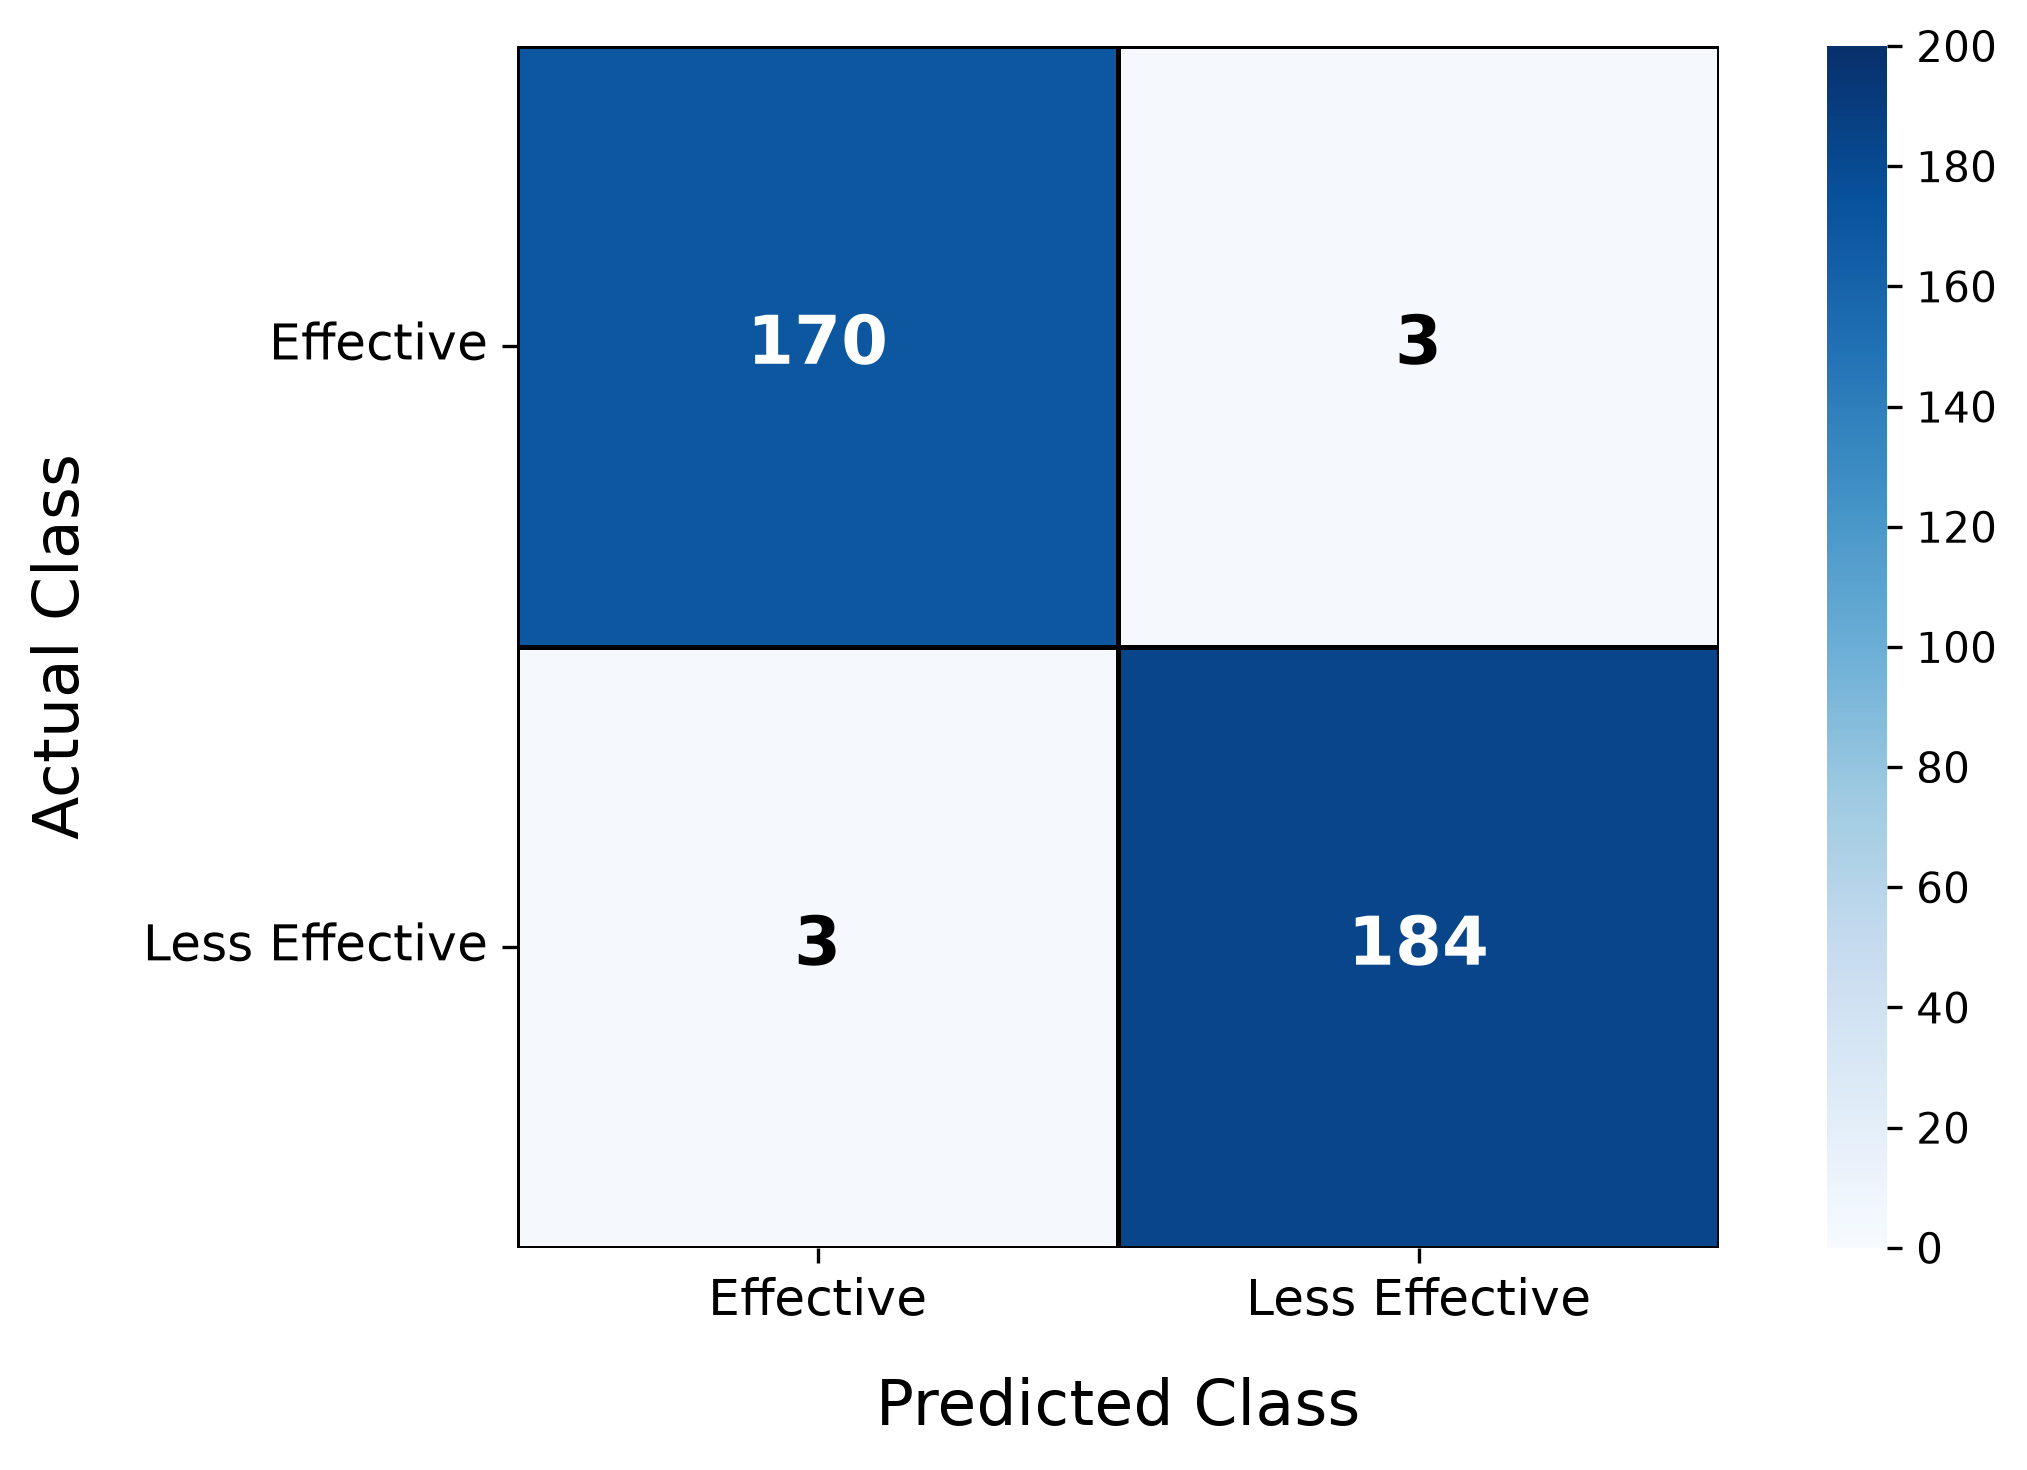

In [29]:
# ============================================================
# CONFUSION MATRIX - PROPOSED DBN MODEL
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

# -------------------- CONFIGURATION --------------------

BASE_DIR = r"F:\.0 Work\3805"

PREDICTION_FILE = os.path.join(
    BASE_DIR,
    "Step5_DBN_Optimization",
    "Optimized_DBN_Test_Predictions.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Confusion_Matrix"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

CLASS_NAMES = ["Effective", "Less_Effective"]

# -------------------- LOAD PREDICTIONS --------------------

print("\n" + "=" * 65)
print("CONFUSION MATRIX - PROPOSED DBN MODEL")
print("=" * 65)

df = pd.read_csv(PREDICTION_FILE)

print("\n[1] LOADED PREDICTION DATA")
print("Dataset Shape:", df.shape)
print("Available Columns:", df.columns.tolist())

# Automatically identify actual and predicted label columns
actual_candidates = [
    "Actual", "Actual_Label", "True_Label",
    "y_true", "Actual_Class"
]

predicted_candidates = [
    "Predicted", "Predicted_Label", "Prediction",
    "y_pred", "Predicted_Class"
]

actual_col = next(
    (c for c in actual_candidates if c in df.columns), None
)

predicted_col = next(
    (c for c in predicted_candidates if c in df.columns), None
)

if actual_col is None or predicted_col is None:
    raise ValueError(
        "Could not identify actual/predicted columns. "
        "Check the prediction CSV column names."
    )

y_true = df[actual_col]
y_pred = df[predicted_col]

# -------------------- ENCODE LABELS --------------------

label_mapping = {
    "Effective": 0,
    "Less_Effective": 1,
    "0": 0,
    "1": 1
}

def encode_labels(values):
    encoded = []

    for value in values:
        value_str = str(value).strip()

        if value_str in label_mapping:
            encoded.append(label_mapping[value_str])
        else:
            try:
                numeric_value = int(float(value_str))
                if numeric_value not in [0, 1]:
                    raise ValueError
                encoded.append(numeric_value)
            except ValueError:
                raise ValueError(
                    f"Unknown label encountered: {value_str}"
                )

    return np.array(encoded, dtype=int)

y_true = encode_labels(y_true)
y_pred = encode_labels(y_pred)

# -------------------- COMPUTE CONFUSION MATRIX --------------------

print("\n[2] COMPUTING CONFUSION MATRIX")

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

# -------------------- SAVE CONFUSION MATRIX --------------------

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual_{name}" for name in CLASS_NAMES],
    columns=[f"Predicted_{name}" for name in CLASS_NAMES]
)

cm_csv = os.path.join(
    OUTPUT_DIR,
    "DBN_Confusion_Matrix.csv"
)

cm_df.to_csv(cm_csv)

print("[3] CONFUSION MATRIX SAVED:", cm_csv)

# -------------------- GENERATE FIGURE --------------------

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    linewidths=0.5,
    linecolor="black",
    annot_kws={"size": 14, "weight": "bold"}
)

plt.title(
    "",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Class", fontsize=12, fontweight="bold")
plt.ylabel("Actual Class", fontsize=12, fontweight="bold")

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()

figure_path = os.path.join(
    OUTPUT_DIR,
    "DBN_Confusion_Matrix.png"
)

plt.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close()

In [26]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import shap
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report

warnings.filterwarnings("ignore")

# ============================================================
# 1. CONFIGURATION
# ============================================================

BASE_DIR = r"F:\.0 Work\3805"

STEP2_DIR = os.path.join(
    BASE_DIR, "Step2_Preprocessing"
)

STEP5_DIR = os.path.join(
    BASE_DIR, "Step5_DBN_Optimization"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR, "SHAP_Analysis"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    STEP5_DIR,
    "Optimized_DBN_Model.pth"
)

SEED = 42
BACKGROUND_SIZE = 100
EXPLAIN_SIZE = 100
SHAP_NSAMPLES = 100

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("\n" + "=" * 75)
print("SHAP EXPLAINABILITY ANALYSIS - OPTIMIZED DBN")
print("=" * 75)

print("Execution Device:", DEVICE)

# ============================================================
# 2. LOAD DATA
# ============================================================

print("\n[1] LOADING DATASET")

X_train_df = pd.read_csv(
    os.path.join(STEP2_DIR, "X_train.csv")
)

X_test_df = pd.read_csv(
    os.path.join(STEP2_DIR, "X_test.csv")
)

feature_names = X_train_df.columns.tolist()

X_train = X_train_df.to_numpy(dtype=np.float32)
X_test = X_test_df.to_numpy(dtype=np.float32)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)
print("Number of Features:", len(feature_names))

# ============================================================
# 3. LOAD CHECKPOINT
# ============================================================

print("\n[2] LOADING OPTIMIZED DBN CHECKPOINT")

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"Model checkpoint not found: {MODEL_PATH}"
    )

try:
    checkpoint = torch.load(
        MODEL_PATH,
        map_location="cpu",
        weights_only=False
    )
except TypeError:
    checkpoint = torch.load(
        MODEL_PATH,
        map_location="cpu"
    )

if isinstance(checkpoint, dict):

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]

    else:
        state_dict = checkpoint

else:
    raise ValueError(
        "Unsupported checkpoint format. Expected a state dictionary."
    )

# Remove DataParallel prefix if present
state_dict = {
    key.replace("module.", ""): value
    for key, value in state_dict.items()
}

print("\nCheckpoint Parameters:")

for key, value in state_dict.items():
    if torch.is_tensor(value):
        print(f"{key}: {tuple(value.shape)}")

# ============================================================
# 4. RECONSTRUCT THE ORIGINAL DBN ARCHITECTURE
# ============================================================

print("\n[3] RECONSTRUCTING DBN ARCHITECTURE")

required_keys = [
    "rbm1.W",
    "rbm1.visible_bias",
    "rbm1.hidden_bias",
    "rbm2.W",
    "rbm2.visible_bias",
    "rbm2.hidden_bias",
    "fc1.weight",
    "fc1.bias",
    "output_layer.weight",
    "output_layer.bias"
]

missing = [
    key for key in required_keys
    if key not in state_dict
]

if missing:
    raise KeyError(
        f"Missing checkpoint parameters: {missing}"
    )


# RBM module matching the checkpoint parameter names
class RBMLayer(nn.Module):

    def __init__(self, visible_units, hidden_units):

        super().__init__()

        self.W = nn.Parameter(
            torch.zeros(visible_units, hidden_units)
        )

        self.visible_bias = nn.Parameter(
            torch.zeros(visible_units)
        )

        self.hidden_bias = nn.Parameter(
            torch.zeros(hidden_units)
        )

    def forward(self, x):

        return torch.sigmoid(
            torch.matmul(x, self.W) + self.hidden_bias
        )


# DBN architecture matching saved Step5 keys
class OptimizedDBN(nn.Module):

    def __init__(
        self,
        input_dim,
        rbm1_hidden,
        rbm2_hidden,
        fc_hidden,
        output_dim
    ):

        super().__init__()

        self.rbm1 = RBMLayer(
            input_dim,
            rbm1_hidden
        )

        self.rbm2 = RBMLayer(
            rbm1_hidden,
            rbm2_hidden
        )

        self.fc1 = nn.Linear(
            rbm2_hidden,
            fc_hidden
        )

        self.output_layer = nn.Linear(
            fc_hidden,
            output_dim
        )

    def forward(self, x):

        x = self.rbm1(x)

        x = self.rbm2(x)

        x = torch.relu(
            self.fc1(x)
        )

        x = self.output_layer(x)

        return x


# Infer dimensions from checkpoint weights
rbm1_shape = state_dict["rbm1.W"].shape
rbm2_shape = state_dict["rbm2.W"].shape
fc1_shape = state_dict["fc1.weight"].shape
output_shape = state_dict["output_layer.weight"].shape

input_dim = rbm1_shape[0]
rbm1_hidden = rbm1_shape[1]

rbm2_hidden = rbm2_shape[1]

fc_hidden = fc1_shape[0]
output_dim = output_shape[0]

# Verify dimensions
if rbm2_shape[0] != rbm1_hidden:
    raise ValueError(
        "RBM1 output and RBM2 input dimensions do not match."
    )

if fc1_shape[1] != rbm2_hidden:
    raise ValueError(
        "RBM2 output and FC1 input dimensions do not match."
    )

if output_shape[1] != fc_hidden:
    raise ValueError(
        "FC1 output and classification layer dimensions do not match."
    )

if input_dim != X_train.shape[1]:
    raise ValueError(
        f"Checkpoint expects {input_dim} features, "
        f"but dataset contains {X_train.shape[1]}."
    )

print("\nDetected Architecture:")
print(f"Input Features : {input_dim}")
print(f"RBM Layer 1    : {input_dim} -> {rbm1_hidden}")
print(f"RBM Layer 2    : {rbm1_hidden} -> {rbm2_hidden}")
print(f"FC Layer       : {rbm2_hidden} -> {fc_hidden}")
print(f"Output Layer   : {fc_hidden} -> {output_dim}")

# ============================================================
# 5. INITIALIZE AND LOAD MODEL
# ============================================================

print("\n[4] LOADING TRAINED MODEL WEIGHTS")

model = OptimizedDBN(
    input_dim=input_dim,
    rbm1_hidden=rbm1_hidden,
    rbm2_hidden=rbm2_hidden,
    fc_hidden=fc_hidden,
    output_dim=output_dim
).to(DEVICE)

model.load_state_dict(
    state_dict,
    strict=True
)

model.eval()

print("Optimized DBN Model Loaded Successfully")

# ============================================================
# 6. DEFINE PREDICTION FUNCTION
# ============================================================

def predict_probability(data):

    data = np.asarray(
        data,
        dtype=np.float32
    )

    tensor_data = torch.tensor(
        data,
        dtype=torch.float32,
        device=DEVICE
    )

    model.eval()

    with torch.no_grad():

        outputs = model(tensor_data)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

    return probabilities.cpu().numpy()


# ============================================================
# 7. SELECT BACKGROUND AND EXPLANATION SAMPLES
# ============================================================

print("\n[5] SELECTING SHAP SAMPLES")

rng = np.random.default_rng(SEED)

background_indices = rng.choice(
    len(X_train),
    size=min(BACKGROUND_SIZE, len(X_train)),
    replace=False
)

explain_indices = rng.choice(
    len(X_test),
    size=min(EXPLAIN_SIZE, len(X_test)),
    replace=False
)

background_data = X_train[background_indices]

explain_data = X_test[explain_indices]

print("Background Samples:", len(background_data))
print("Explanation Samples:", len(explain_data))

# ============================================================
# 8. COMPUTE SHAP VALUES
# ============================================================

print("\n[6] COMPUTING SHAP VALUES")
print("SHAP KernelExplainer is running...")

explainer = shap.KernelExplainer(
    predict_probability,
    background_data
)

shap_values = explainer.shap_values(
    explain_data,
    nsamples=SHAP_NSAMPLES
)

# ============================================================
# 9. EXTRACT POSITIVE-CLASS SHAP VALUES
# ============================================================

print("\n[7] PROCESSING SHAP VALUES")

# Explain class index 1: Less_Effective
if isinstance(shap_values, list):

    shap_values_class = np.asarray(
        shap_values[1]
    )

else:

    shap_array = np.asarray(shap_values)

    if shap_array.ndim == 3:

        if shap_array.shape[-1] == output_dim:
            shap_values_class = shap_array[:, :, 1]

        elif shap_array.shape[0] == output_dim:
            shap_values_class = shap_array[1]

        else:
            raise ValueError(
                f"Unexpected SHAP dimensions: {shap_array.shape}"
            )

    elif shap_array.ndim == 2:

        shap_values_class = shap_array

    else:

        raise ValueError(
            f"Unexpected SHAP dimensions: {shap_array.shape}"
        )

shap_values_class = np.asarray(
    shap_values_class,
    dtype=np.float64
)

if shap_values_class.shape != explain_data.shape:

    raise ValueError(
        f"SHAP shape {shap_values_class.shape} "
        f"does not match input shape {explain_data.shape}"
    )

print("SHAP Values Shape:", shap_values_class.shape)

# ============================================================
# 10. SAVE SHAP VALUES AND FEATURE IMPORTANCE
# ============================================================

print("\n[8] SAVING SHAP RESULTS")

shap_df = pd.DataFrame(
    shap_values_class,
    columns=feature_names
)

shap_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DBN_SHAP_Values.csv"
    ),
    index=False
)

importance = np.mean(
    np.abs(shap_values_class),
    axis=0
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": importance
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

importance_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DBN_SHAP_Feature_Importance.csv"
    ),
    index=False
)

print("\nSHAP Feature Importance:")
print(
    importance_df.to_string(index=False)
)

# ============================================================
# 11. SHAP SUMMARY PLOT
# ============================================================

print("\n[9] GENERATING SHAP SUMMARY PLOT")

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values_class,
    explain_data,
    feature_names=feature_names,
    show=False
)

plt.title(
    "SHAP Summary Plot - Optimized DBN",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "DBN_SHAP_Summary.png"
    ),
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.close()

# ============================================================
# 12. SHAP BAR PLOT
# ============================================================

print("\n[10] GENERATING SHAP BAR PLOT")

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values_class,
    explain_data,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.title(
    "SHAP Feature Importance - Optimized DBN",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "DBN_SHAP_Feature_Importance.png"
    ),
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.close()

# ============================================================
# 13. SHAP WATERFALL PLOT
# ============================================================

print("\n[11] GENERATING SHAP WATERFALL PLOT")

expected_value = np.asarray(
    explainer.expected_value
).reshape(-1)

base_value = float(
    expected_value[1]
)

waterfall_explanation = shap.Explanation(
    values=shap_values_class[0],
    base_values=base_value,
    data=explain_data[0],
    feature_names=feature_names
)

shap.plots.waterfall(
    waterfall_explanation,
    max_display=len(feature_names),
    show=False
)

plt.title(
    "SHAP Waterfall Plot - Optimized DBN",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "DBN_SHAP_Waterfall.png"
    ),
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.close()

# ============================================================
# 14. SHAP RESULTS SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("SHAP ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 75)

print("\nExplained Class: Less_Effective (Class 1)")

print("\nTop 5 Important Features:")

print(
    importance_df.head(5).to_string(index=False)
)

print("\nGenerated Files:")

for filename in [
    "DBN_SHAP_Values.csv",
    "DBN_SHAP_Feature_Importance.csv",
    "DBN_SHAP_Summary.png",
    "DBN_SHAP_Feature_Importance.png",
    "DBN_SHAP_Waterfall.png"
]:

    print(
        os.path.join(OUTPUT_DIR, filename)
    )

print("\nOutput Directory:", OUTPUT_DIR)

print("=" * 75)


SHAP EXPLAINABILITY ANALYSIS - OPTIMIZED DBN
Execution Device: cpu

[1] LOADING DATASET
Training Shape: (1440, 9)
Testing Shape: (360, 9)
Number of Features: 9

[2] LOADING OPTIMIZED DBN CHECKPOINT

Checkpoint Parameters:
rbm1.W: (9, 64)
rbm1.visible_bias: (9,)
rbm1.hidden_bias: (64,)
rbm2.W: (64, 32)
rbm2.visible_bias: (64,)
rbm2.hidden_bias: (32,)
fc1.weight: (32, 32)
fc1.bias: (32,)
output_layer.weight: (2, 32)
output_layer.bias: (2,)

[3] RECONSTRUCTING DBN ARCHITECTURE

Detected Architecture:
Input Features : 9
RBM Layer 1    : 9 -> 64
RBM Layer 2    : 64 -> 32
FC Layer       : 32 -> 32
Output Layer   : 32 -> 2

[4] LOADING TRAINED MODEL WEIGHTS
Optimized DBN Model Loaded Successfully

[5] SELECTING SHAP SAMPLES
Background Samples: 100
Explanation Samples: 100

[6] COMPUTING SHAP VALUES
SHAP KernelExplainer is running...


  0%|          | 0/100 [00:00<?, ?it/s]


[7] PROCESSING SHAP VALUES
SHAP Values Shape: (100, 9)

[8] SAVING SHAP RESULTS

SHAP Feature Importance:
              Feature  Mean_Absolute_SHAP
       Pre_Confidence            0.005251
      Post_Confidence            0.004668
          Pre_Anxiety            0.003131
         Post_Anxiety            0.002867
                  Age            0.001037
Pre_Performance_Score            0.000892
          Gender_Male            0.000694
        Gender_Female            0.000687
     Experience_Years            0.000645

[9] GENERATING SHAP SUMMARY PLOT

[10] GENERATING SHAP BAR PLOT

[11] GENERATING SHAP WATERFALL PLOT

SHAP ANALYSIS COMPLETED SUCCESSFULLY

Explained Class: Less_Effective (Class 1)

Top 5 Important Features:
        Feature  Mean_Absolute_SHAP
 Pre_Confidence            0.005251
Post_Confidence            0.004668
    Pre_Anxiety            0.003131
   Post_Anxiety            0.002867
            Age            0.001037

Generated Files:
F:\.0 Work\3805\SHAP_Analysis


[9] SHAP SUMMARY PLOT


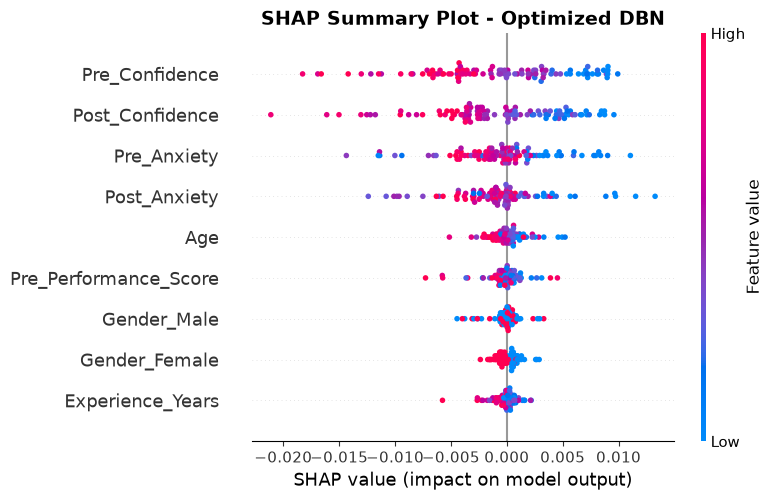


[10] SHAP FEATURE IMPORTANCE


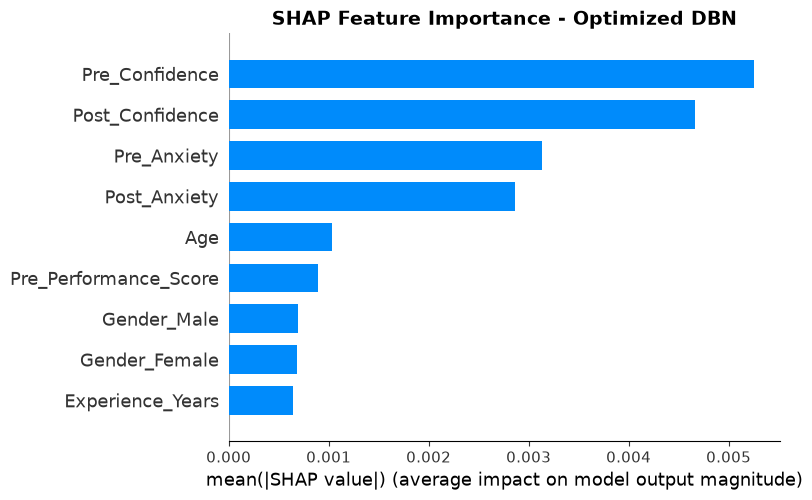


[11] SHAP WATERFALL PLOT


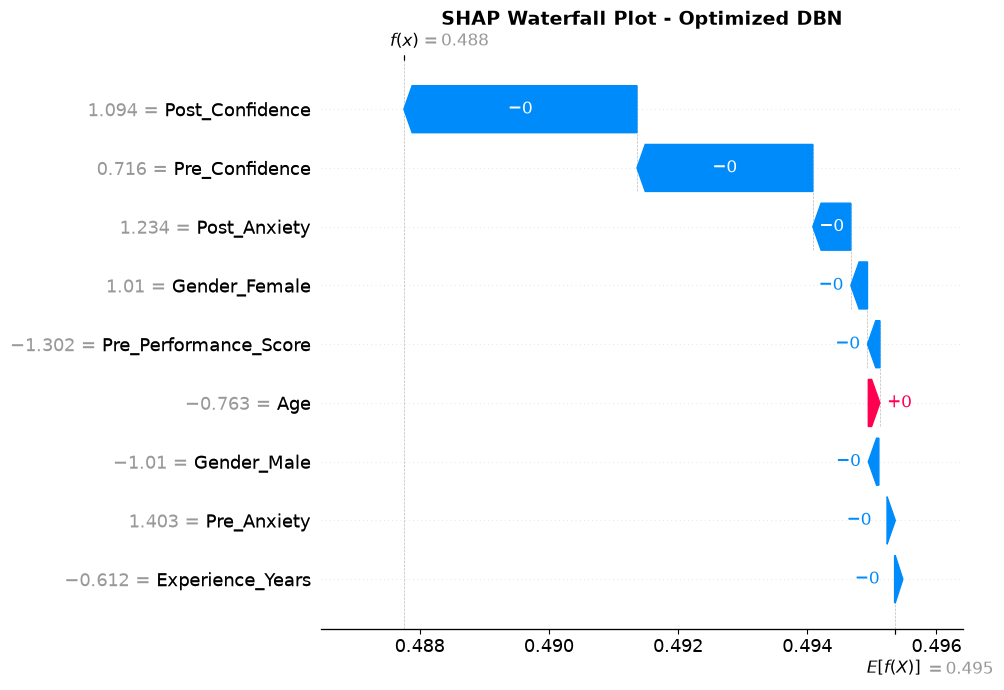


[12] TOP SHAP FEATURES


,Feature,Mean_Absolute_SHAP
0,Pre_Confidence,0.005251
1,Post_Confidence,0.004668
2,Pre_Anxiety,0.003131
3,Post_Anxiety,0.002867
4,Age,0.001037
5,Pre_Performance_Score,0.000892
6,Gender_Male,0.000694
7,Gender_Female,0.000687
8,Experience_Years,0.000645



SHAP OUTPUT DIRECTORY:
F:\.0 Work\3805\SHAP_Analysis

SHAP VISUALIZATION COMPLETED


In [27]:
# ============================================================
# 11. DISPLAY SHAP SUMMARY PLOT
# ============================================================

print("\n[9] SHAP SUMMARY PLOT")

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values_class,
    explain_data,
    feature_names=feature_names,
    show=False
)

plt.title(
    "SHAP Summary Plot - Optimized DBN",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "DBN_SHAP_Summary.png"),
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close()


# ============================================================
# 12. DISPLAY SHAP FEATURE IMPORTANCE
# ============================================================

print("\n[10] SHAP FEATURE IMPORTANCE")

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values_class,
    explain_data,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.title(
    "SHAP Feature Importance - Optimized DBN",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "DBN_SHAP_Feature_Importance.png"
    ),
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close()


# ============================================================
# 13. DISPLAY SHAP WATERFALL PLOT
# ============================================================

print("\n[11] SHAP WATERFALL PLOT")

expected_value = np.asarray(
    explainer.expected_value
).reshape(-1)

base_value = float(expected_value[1])

waterfall_explanation = shap.Explanation(
    values=shap_values_class[0],
    base_values=base_value,
    data=explain_data[0],
    feature_names=feature_names
)

shap.plots.waterfall(
    waterfall_explanation,
    max_display=len(feature_names),
    show=False
)

plt.gcf().set_size_inches(10, 7)

plt.title(
    "SHAP Waterfall Plot - Optimized DBN",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "DBN_SHAP_Waterfall.png"
    ),
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close()


# ============================================================
# 14. DISPLAY TOP FEATURE IMPORTANCE TABLE
# ============================================================

print("\n[12] TOP SHAP FEATURES")

display(
    importance_df.reset_index(drop=True)
)

print("\nSHAP OUTPUT DIRECTORY:")
print(OUTPUT_DIR)

print("\nSHAP VISUALIZATION COMPLETED")